# 1-board: pos-coupling

Measure what the board adds to the position reading, the board NTC, the chip's 1.2 V reference, the rail tap and the terminal taps when the bridge drives a load and nothing can move, with a fixed divider in the pot's place.

## Purpose

Two stage 3 readings on mg90-d would need the board to couple several counts per amp into `pos`. In the locked-horn laps of [resistance](../../3-servo/resistance/resistance.ipynb), `locked-4` at 100 % duty, the pot read 7.4 counts under its baseline in both directions at about 0.77 A. In [steps](../../3-servo/steps/steps.ipynb) the raw pot reads higher while the bridge drives -1, about 23 counts per amp of plugging current, and the -1 starts read 2.6 to 4 counts higher before any motion. Either could be the servo, the pot, or the board between the POS connector and the ADC. A board that couples a few counts per amp into `pos` would explain both.

This experiment takes the servo out. A divider of fixed resistors sits on the POS connector in the pot's place, so the voltage at POS1 has no reason to move, and the bridge drives a load with no moving parts. Whatever `pos` does under drive comes from the board. The same sweeps read the board NTC, the rail tap, the shunt and the terminal taps, which answer the same question for their own nodes, and the second capture reads the chip's 1.2 V reference in every row, which gives VDD at the sample.

A shift that follows the current whatever the duty and the decay, with the same sign in both directions and present at 100 % where the bridge stops switching, is a DC drop in copper the return current shares with the reading. One that follows the duty or the decay and is gone at 100 % is coupling from the switching bridge.

## Procedure

`capture.py` drives the sweeps. The divider is 3.3 k from the connector's 3V3 pin to POS1 and 2.2 k from POS1 to its GND pin, which puts `pos` at about 1632 counts behind a 1.32 k source. The load is the RL dummy on the motor terminals. The capture script's docstring names the bare 5 ohm resistor with both power inductors in series, but the dummy's V/I and its time constant, in the last results section, read the resistor and one inductor, so both captures ran on the resistor plus one inductor. No meter is used.

Each capture is 18 sweeps, three rails at 3.7, 5.0 and 7.4 V, three repeats on each rail and both decay modes in each repeat. A sweep is a 1 s torque-off baseline, then rungs at 10, 20, 40, 60, 80 and 100 % duty in direction +1 and the same in direction -1, 300 ms each with a 500 ms torque-off rest between them. At 100 % the bridge holds one leg high and one low for the whole rung and nothing switches. The current runs from about 60 mA to 1.3 A, and each duty meets it at three currents.

1. capture-1. The row carries `pos`, `vbus_raw`, `ntc_raw`, `current_raw`, `vmotor_a` and `vmotor_b`.
2. capture-2, with the script's `vref` argument. The row trades `vmotor_b` for `vref_raw`, the 1.2 V reference read as a share of VDD. `pos` and the NTC are dividers from VDD, so a slow VDD move cancels on them, while `vref_raw` reads VDD itself, $n_\mathrm{ref} = 1.2\,\mathrm{V} \times 4096 / V_\mathrm{DD}$. A VDD dip reads `vref_raw` up, and a divider node whose filter holds it through the dip reads up with it.

## Data

`sweeps.csv` in each capture names each sweep's folder, rail, decay and repeat, and in capture-2 the row. Each `sweeps/<k>/` holds `sweep.csv`, one row per control tick at 20 kHz with the raw channels in counts, `segments.csv`, one row per segment with its commanded duty, direction and host times, and `meta.json`, the board's sense block and the decay.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oscnb import boards, figures, results, scales, tel
from oscnb.display import show
from oscnb.figures import BLUE, GREEN, INK, MUTED, ORANGE

BOARD = boards.BOARDS[boards.DEFAULT]   # the board, its parts' nominal values
TELEMETRY = Path("../../../telemetry") / BOARD.key
DATASET = (TELEMETRY / "pos-coupling").resolve()
CAPTURES = ("capture-1", "capture-2")
FS = BOARD.tick_hz                      # rows per second, the control rate
US_PER_ROW = 1e6 / FS                   # us, one row
RAIL_COLOR = {3.7: BLUE, 5.0: ORANGE, 7.4: GREEN}   # one color per rail
DECAY_MARKER = {"slow": "o", "fast": "s"}
print(BOARD.key, "from", results.rel(DATASET))

dev-v006-2A-D from telemetry/dev-v006-2A-D/pos-coupling


The method's constants, each with its unit and the reason for its value.

In [2]:
DUTIES = [10, 20, 40, 60, 80, 100]   # %, the rungs of every sweep
RAILS = (3.7, 5.0, 7.4)              # V, the three rails
SKIP = 200          # rows, 10 ms: the stream opens 0 to 9 rows before the
                    # drive, and the dummy's L/R is 0.17 ms
FRAME = 16          # rows, one TEL frame, the frame pattern's period
EDGE_COUNTS = 100   # counts, the drive's first row: the taps this far apart
                    # (capture-1) or the current this far over its zero
PEAK_ROWS = 40      # rows, 2 ms after the edge, where an onset peak is read
SETTLED_SHARE = 0.001   # an onset is back within 0.1 % of its rung
FULL = (6, 12)      # the 100 % rungs' segments, one per direction
I_LOCKED_A = 0.77   # A, the locked-horn laps' current
MATCHED = [[(3.7, 20), (5.0, 10), (7.4, 10)],      # (rail, duty) sets of
           [(3.7, 40), (5.0, 20), (7.4, 20)],      # slow-decay rungs at
           [(3.7, 80), (5.0, 60), (7.4, 40)],      # about one current
           [(3.7, 100), (5.0, 80), (7.4, 60)]]
RAIL_FROM_DUTY = 40  # %, the rail slot sits in the drive window from here
HIST_CODES = np.arange(1628, 1639)   # pos codes the histograms span

The stage 1 results this notebook reads its conversions and timings from.

In [3]:
S = scales.load(BOARD)          # stage 1's current, terminal and rail lines
TC = S.terminal_chain
NTC = results.read("1-board", "ntc-curve", BOARD.key)
REST = results.read("1-board", "rest-noise", BOARD.key)
BRIDGE = results.read("1-board", "bridge-states", BOARD.key)
TIMING = results.read("1-board", "sample-timing", BOARD.key)
VDD_MV = TC["vdd_v"]["value"] * 1e3     # mV, VDD from 3.7 V up
# the NTC through the registry's nominal beta, the conversion ntc-curve grades
assert BOARD.ntc_beta == NTC["beta_nominal"]["value"]
S.describe()
print(f"VDD {VDD_MV:.0f} mV, NTC floor at rest "
      f"{REST['ntc_noise']['value']:.2f} counts rms")

current: counts over the zero = +5.3 + 1135.0 x amps (1133.8 to 1136.3), graded over 0.23 to 1.31 A
terminals: tap difference = +2.4 + 248.37 x volts (248.20 to 248.53)
rail: tap = +6.0 + 247.54 x volts at rest
bridge ON edge 40 ticks after the commanded start, shunt crossing 44, OFF edge 14 after the commanded end, shunt settled 72 after the start
fast decay: ON edge 8 ticks after the commanded start, OFF edge 12 after the end
VDD 3293 mV, NTC floor at rest 1.15 counts rms


### sweeps.csv

The sweeps of capture-2, and every sweep of both captures loaded once.

In [4]:
SWEEPS = {cap: pd.read_csv(DATASET / cap / "sweeps.csv") for cap in CAPTURES}


def load_sweep(cap, k):
    # (frame, meta, segments) of sweep k, the sense block checked
    folder = DATASET / cap / "sweeps" / str(k)
    df, meta = tel.load(folder, BOARD)      # raises on a sense mismatch
    assert tel.board_of(meta).key == BOARD.key
    return df, meta, pd.read_csv(folder / "segments.csv")


DATA = {(cap, int(k)): load_sweep(cap, int(k))
        for cap in CAPTURES for k in SWEEPS[cap]["k"]}
assert (SWEEPS["capture-2"]["row"] == "0x238+12").all()
show(SWEEPS["capture-2"], n=6)
for cap in CAPTURES:
    sw = SWEEPS[cap]
    missing = sum(int(tel.gaps(DATA[(cap, int(k))][0]).sum())
                  for k in sw["k"])
    print(f"{cap}: {len(sw)} sweeps, rails "
          f"{sorted(sw['volts_set'].unique())} read "
          f"{sw['vsys_read'].min():.3f} to {sw['vsys_read'].max():.3f} V, "
          f"missing rows {missing}")

,k,volts_set,dps_read,vsys_read,decay,repeat,row,t_start,t_end,folder
0,0,3.700,3.950,3.693,slow,0,0x238+12,1794178461.956,1794178475.338,sweeps/0
1,1,3.700,3.950,3.693,fast,0,0x238+12,1794178475.339,1794178488.754,sweeps/1
2,2,3.700,3.950,3.693,slow,1,0x238+12,1794178488.755,1794178502.223,sweeps/2
3,3,3.700,3.950,3.693,fast,1,0x238+12,1794178502.223,1794178515.712,sweeps/3
4,4,3.700,3.950,3.693,slow,2,0x238+12,1794178515.712,1794178529.052,sweeps/4
5,5,3.700,3.950,3.693,fast,2,0x238+12,1794178529.053,1794178542.412,sweeps/5


capture-1: 18 sweeps, rails [np.float64(3.7), np.float64(5.0), np.float64(7.4)] read 3.691 to 7.375 V, missing rows 0
capture-2: 18 sweeps, rails [np.float64(3.7), np.float64(5.0), np.float64(7.4)] read 3.693 to 7.396 V, missing rows 0


### sweeps/K/sweep.csv

The first sweep of capture-2, 3.7 V in slow decay, `pos`, `vref_raw`, the NTC and the current, row by row. The rests between the rungs are not streamed, so the rows join end to end. The thing to see is how small anything on `pos` is next to its own noise.

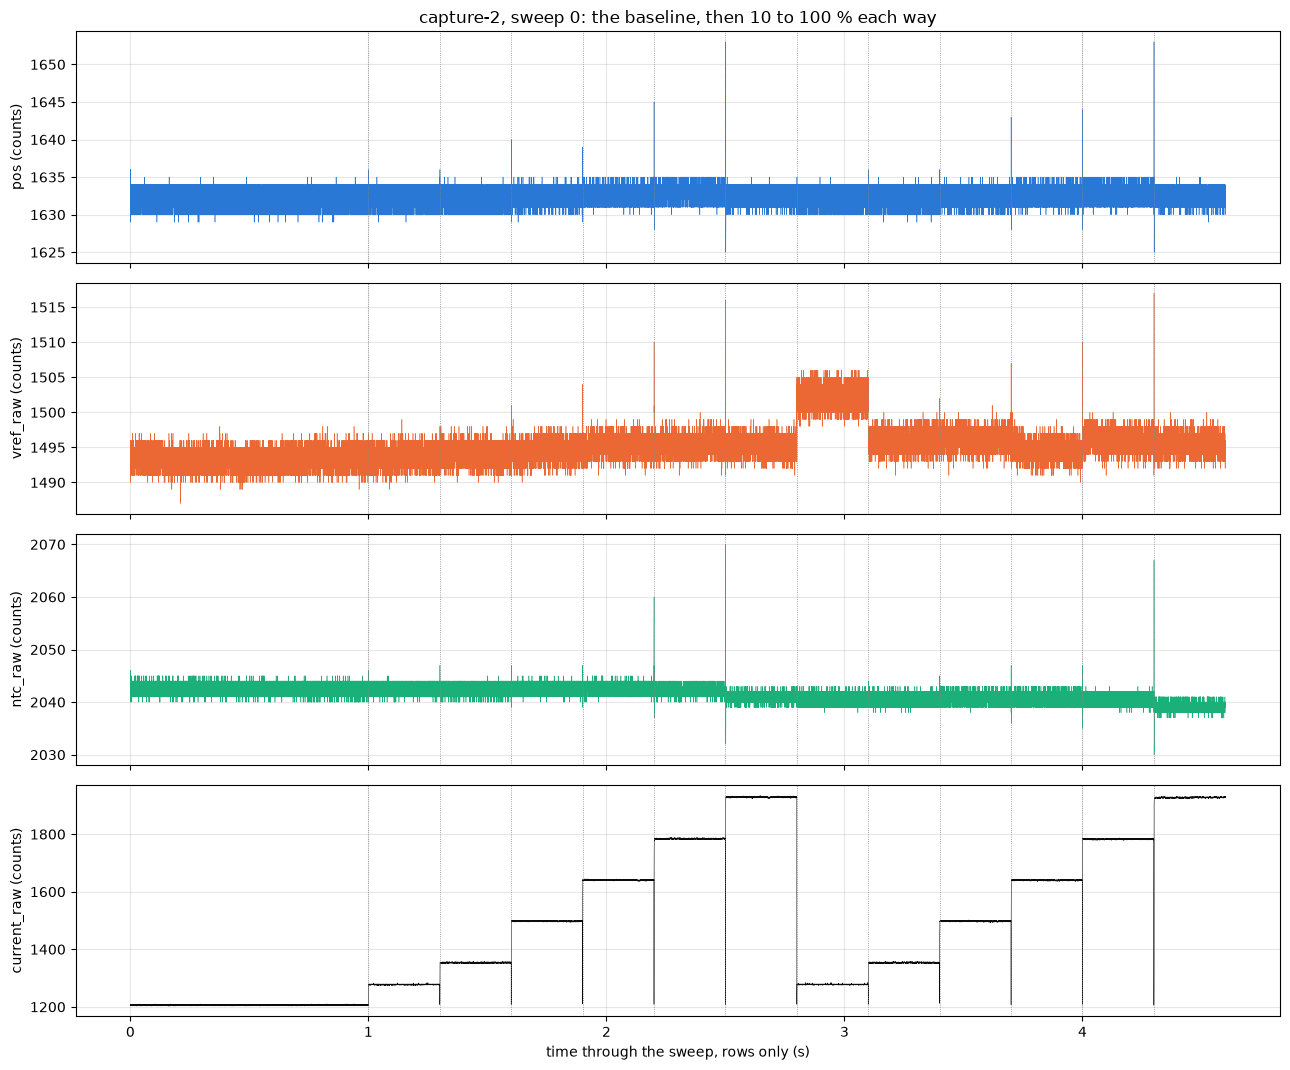

In [5]:
df0 = DATA[("capture-2", 0)][0]
channels = [("pos (counts)", [(df0["pos"], BLUE)]),
            ("vref_raw (counts)", [(df0["vref_raw"], ORANGE)]),
            ("ntc_raw (counts)", [(df0["ntc_raw"], GREEN)]),
            ("current_raw (counts)", [(df0["current_raw"], INK)])]
fig, ax = figures.sweep_overview(
    df0, FS, channels,
    title="capture-2, sweep 0: the baseline, then 10 to 100 % each way")
figures.finish(fig)

The current steps up with each rung, and `pos`, `vref_raw` and the NTC sit within a few counts of their baselines throughout, the NTC drifting down a little as the board warms. Short spikes at the rungs' starts show on all three, largest at 100 %. `vref_raw` also sits about 8 counts higher through the first rung of direction -1, slow 10 %, which the edge section takes up. The sections below take the shifts out of that noise by averaging thousands of rows per rung.

## Method

Every rung is read against its own sweep's baseline, the second half of the torque-off segment (`tel.baseline`). A rung's reading is the mean over its rows 200 to 6000, leaving out the first 10 ms, and its shift is that mean less the baseline's. The rungs come 0.92 s apart in capture-1 and 1.02 s in capture-2, from `segments.csv`. Every error is one standard error, and a group of n 6 is three repeats times two directions. Those errors understate the run-to-run floor of about 0.1 count that the 100 % control shows.

The load current is read from the crest shunt sample. In slow decay the crest is the load current, less the in-drive offset, and at 100 % it is the same in both decays. At fast 60 and 80 % the current flows the whole period and the crest lands in the diode return, whose size is the load current. At fast 10 to 40 % the current returns to zero every period, the crest reads the return's tail, and no load current is assigned, since the slow sibling overstates it by 5 to 10 times.

The NTC drifts with the board's heating and `vref_raw` a little, so each takes one line per rail through its 6 baselines against time, and a rung's shift has the line's rate times its time after the baseline taken off.

At a rung's onset the rows are aligned on the drive's first row, where the taps are 100 counts apart in capture-1 or the current is 100 counts over its zero in capture-2, and the frame pattern, the baseline's mean by row of the 16-row TEL frame, is taken off each channel row by row. In capture-2 each channel is read as a share of its baseline, $s = n / n_0 - 1$. With `vref_raw` reading $1.2\,\mathrm{V} \times 4096 / V_\mathrm{DD}$, a share $s$ on it is a VDD dip of

$$\Delta V_\mathrm{DD} = V_\mathrm{DD} \, \frac{s}{1 + s}$$

with $V_\mathrm{DD}$ = 3293 mV from terminal-chain. A divider from VDD whose node is held by its filter reads up by the same share as `vref_raw`, and one that follows VDD at once reads nothing.

The edges are placed in timer ticks after the crest, 2400 ticks a PWM period, a half window of $D \times 1200$ ticks, slow decay's ON and OFF lags from sample-timing's line through the rails, fast decay's from bridge-states, and the fast return's end from bridge-states' return time on the one-inductor wiring. The slot apertures come from sample-timing's crest slots and the scan's slot pitch.

The helpers every section uses.

In [6]:
def duty_of(seg_row):
    # a rung's duty in %, from its commanded q15
    return int(round(abs(seg_row["cmd_duty_q15"]) / 32767 * 100))


def settled(df, s):
    # rung s's rows past the first SKIP, rows 200 to 6000
    return df[df["seg"] == s].iloc[SKIP:]


def se(x):
    # the standard error of the finite values of x
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    if len(x) < 2:
        return np.nan
    return x.std(ddof=1) / np.sqrt(len(x))


def pattern(base, column):
    # the frame pattern: the mean by row of the TEL frame less the mean
    by_row = base.groupby(base["tick"] % FRAME)[column].mean()
    return by_row - base[column].mean()


def rail_key(v):
    # a rail as a results key, 3.7 V as 3v7
    return f"{v:.1f}".replace(".", "v")

One row per sweep and rung of a capture, each raw column's settled mean and its baseline.

In [7]:
def rung_table(cap, raw):
    rows = []
    for _, sw in SWEEPS[cap].iterrows():
        df, meta, seg = DATA[(cap, int(sw["k"]))]
        assert meta["decay"] == sw["decay"]
        base = tel.baseline(df)             # seg 0's second half
        zero_i = base["current_raw"].median()
        s0 = seg[seg["seg"] == 0].iloc[0]
        # the baseline's second half is centered 3/4 of the way through
        t_base = s0["t_start"] + 0.75 * (s0["t_end"] - s0["t_start"])
        for _, sr in seg[seg["seg"] > 0].iterrows():
            g = settled(df, int(sr["seg"]))
            span = sr["t_end"] - sr["t_start"]
            r = {"k": int(sw["k"]), "rail": sw["volts_set"],
                 "vsys_read": sw["vsys_read"], "decay": sw["decay"],
                 "repeat": int(sw["repeat"]), "seg": int(sr["seg"]),
                 "dir": int(sr["dir"]), "duty": duty_of(sr), "n": len(g),
                 # the settled window's center after the baseline's, s
                 "t_rel": sr["t_start"] + (SKIP / FS + span) / 2 - t_base,
                 "t_base_abs": t_base, "zero_i": zero_i}
            for c in raw:
                r[c], r[c + "_sd"] = g[c].mean(), g[c].std()
                r[c + "_base"] = base[c].mean()
                r[c + "_base_sd"] = base[c].std()
                r["d_" + c] = r[c] - r[c + "_base"]
            i = r["current_raw"]
            r["i_crest_a"] = float(S.amps(i, zero_i, drive=True))
            r["i_crest_nodrive_a"] = float(S.amps(i, zero_i, drive=False))
            rows.append(r)
    return pd.DataFrame(rows)

The load current by the rules above, and the two captures' tables.

In [8]:
def load_current(R):
    # the crest in slow decay and at 100 %, the return's size at fast 60 and
    # 80 %, none at fast 10 to 40 % where the current stops every period
    crest = (R["decay"] == "slow") | (R["duty"] == 100)
    ret = np.where(R["duty"] >= 60, -R["i_crest_nodrive_a"], np.nan)
    return np.where(crest, R["i_crest_a"], ret)


RAW1 = ["pos", "current_raw", "vmotor_a", "vmotor_b", "vbus_raw", "ntc_raw"]
RAW2 = ["pos", "vref_raw", "vbus_raw", "ntc_raw", "current_raw", "vmotor_a"]
R1 = rung_table("capture-1", RAW1)
R2 = rung_table("capture-2", RAW2)
for name, R in (("capture-1", R1), ("capture-2", R2)):
    R["i_load_a"] = load_current(R)
    print(f"{name}: {len(R)} rungs from {R['k'].nunique()} sweeps, "
          f"{R['n'].min()} to {R['n'].max()} settled rows per rung, rungs "
          f"{np.diff(R[R['k'] == 0]['t_rel']).mean():.2f} s apart")

capture-1: 216 rungs from 18 sweeps, 5800 to 5800 settled rows per rung, rungs 0.92 s apart
capture-2: 216 rungs from 18 sweeps, 5800 to 5800 settled rows per rung, rungs 1.02 s apart


The drift lines, one per rail through the 6 baselines, and each rung's shift less its rail's rate times its time after the baseline.

In [9]:
def drift_lines(R, column):
    # {rail: line of the column's baselines against time, counts/s}
    B = R.groupby("k").first().reset_index()
    t = B["t_base_abs"] - B["t_base_abs"].min()
    return {v: results.fit_line(t[g.index], g[column + "_base"])
            for v, g in B.groupby("rail")}


DRIFT = {("capture-1", "ntc_raw"): drift_lines(R1, "ntc_raw")}
for c in ("ntc_raw", "vref_raw", "pos"):
    DRIFT[("capture-2", c)] = drift_lines(R2, c)
for (cap, c), lines in DRIFT.items():
    R = R1 if cap == "capture-1" else R2
    rate = R["rail"].map({v: f["slope"] for v, f in lines.items()})
    R["dc_" + c] = R["d_" + c] - rate * R["t_rel"]
    rate_se = R["rail"].map({v: f["slope_se"] for v, f in lines.items()})
    R["dc_err_" + c] = rate_se * R["t_rel"]   # the correction's own error
    print(f"{cap} {c}: " + ", ".join(
        f"{v} V {f['slope']:+.4f} +/- {f['slope_se']:.4f}"
        for v, f in lines.items()) + " counts/s")

capture-1 ntc_raw: 3.7 V +0.0210 +/- 0.0079, 5.0 V -0.1390 +/- 0.0072, 7.4 V -0.3193 +/- 0.0107 counts/s
capture-2 ntc_raw: 3.7 V -0.2708 +/- 0.0046, 5.0 V -0.2748 +/- 0.0069, 7.4 V -0.4084 +/- 0.0118 counts/s
capture-2 vref_raw: 3.7 V -0.0021 +/- 0.0057, 5.0 V +0.0073 +/- 0.0036, 7.4 V +0.0011 +/- 0.0037 counts/s
capture-2 pos: 3.7 V +0.0016 +/- 0.0008, 5.0 V +0.0002 +/- 0.0007, 7.4 V -0.0004 +/- 0.0008 counts/s


In capture-1 the NTC rises at 3.7 V and falls at 5 and 7.4 V, -0.32 counts/s at the top rail, the board warming with the rail's power. In capture-2 it falls on every rail. `vref_raw` drifts by under 0.01 count/s and `pos` by under 0.002, so neither needs the line, and capture-2's `pos` shifts below are the raw ones, as in capture-1.

## Results

### The DC coupling on the 100 % rungs

At 100 % nothing switches, so a `pos` shift there is DC. Each 100 % rung's shift against its load current, a line through each capture and through both pooled, the intercept free and through zero, and what each line gives at the locked laps' 0.77 A.

In [10]:
def dc_line(H):
    # the line of the pos shift on the load current, and the line through
    # zero with its standard error and rms
    f = results.fit_line(H["i_load_a"], H["d_pos"])
    x, y = H["i_load_a"].to_numpy(), H["d_pos"].to_numpy()
    f["b0"] = (x * y).sum() / (x * x).sum()
    r0 = y - f["b0"] * x
    f["b0_se"] = np.sqrt((r0 ** 2).sum() / (len(x) - 1) / (x * x).sum())
    f["b0_rms"] = np.sqrt((r0 ** 2).mean())
    return f


H1, H2 = R1[R1["duty"] == 100], R2[R2["duty"] == 100]
cols = ["i_load_a", "d_pos"]
DC = {"capture-1": dc_line(H1), "capture-2": dc_line(H2),
      "pooled": dc_line(pd.concat([H1[cols], H2[cols]]))}
for name, f in DC.items():
    f["at_locked"] = f["intercept"] + I_LOCKED_A * f["slope"]
    f["at_locked_se"] = np.hypot(f["intercept_se"],
                                 I_LOCKED_A * f["slope_se"])
    print(f"{name}: {f['slope']:+.3f} +/- {f['slope_se']:.3f} counts/A, "
          f"intercept {f['intercept']:+.3f} +/- {f['intercept_se']:.3f}, "
          f"rms {f['rms']:.3f}, n {f['n']}; through zero {f['b0']:+.3f} "
          f"+/- {f['b0_se']:.3f}; at {I_LOCKED_A} A {f['at_locked']:+.2f} "
          f"+/- {f['at_locked_se']:.2f} counts")

capture-1: +0.594 +/- 0.051 counts/A, intercept -0.133 +/- 0.049, rms 0.079, n 36; through zero +0.460 +/- 0.015; at 0.77 A +0.32 +/- 0.06 counts
capture-2: +0.531 +/- 0.042 counts/A, intercept -0.085 +/- 0.040, rms 0.066, n 36; through zero +0.446 +/- 0.012; at 0.77 A +0.32 +/- 0.05 counts
pooled: +0.563 +/- 0.033 counts/A, intercept -0.109 +/- 0.032, rms 0.073, n 72; through zero +0.453 +/- 0.010; at 0.77 A +0.32 +/- 0.04 counts


Each direction's line, the slow and fast 100 % rungs at the same rail, which differ only by the run, and `pos` at rest against the rail.

In [11]:
DIR_SLOPE = {}
for name, H in (("capture-1", H1), ("capture-2", H2)):
    for d, g in H.groupby("dir"):
        f = results.fit_line(g["i_load_a"], g["d_pos"])
        DIR_SLOPE[(name, d)] = f
        print(f"{name} dir {d:+d}: {f['slope']:+.3f} +/- "
              f"{f['slope_se']:.3f} counts/A")
for v, g in H1.groupby("rail"):       # the run-to-run floor, capture-1
    slow = g[g["decay"] == "slow"]["d_pos"]
    fast = g[g["decay"] == "fast"]["d_pos"]
    print(f"capture-1 {v} V 100 %: slow - fast "
          f"{slow.mean() - fast.mean():+.3f} +/- "
          f"{np.hypot(se(slow), se(fast)):.3f} counts")
REST1 = R1.groupby("k").first().reset_index()     # one row per sweep
REST_RAIL = results.fit_line(REST1["vsys_read"], REST1["pos_base"])
print(f"pos at rest against the rail: {REST_RAIL['slope']:+.4f} +/- "
      f"{REST_RAIL['slope_se']:.4f} counts/V, n {REST_RAIL['n']}")

capture-1 dir -1: +0.574 +/- 0.076 counts/A
capture-1 dir +1: +0.614 +/- 0.066 counts/A
capture-2 dir -1: +0.488 +/- 0.064 counts/A
capture-2 dir +1: +0.574 +/- 0.050 counts/A
capture-1 3.7 V 100 %: slow - fast +0.117 +/- 0.035 counts
capture-1 5.0 V 100 %: slow - fast -0.027 +/- 0.037 counts
capture-1 7.4 V 100 %: slow - fast -0.116 +/- 0.047 counts
pos at rest against the rail: -0.0049 +/- 0.0098 counts/V, n 18


Every 100 % rung of both captures against its load current with the pooled line, and the residuals under it.

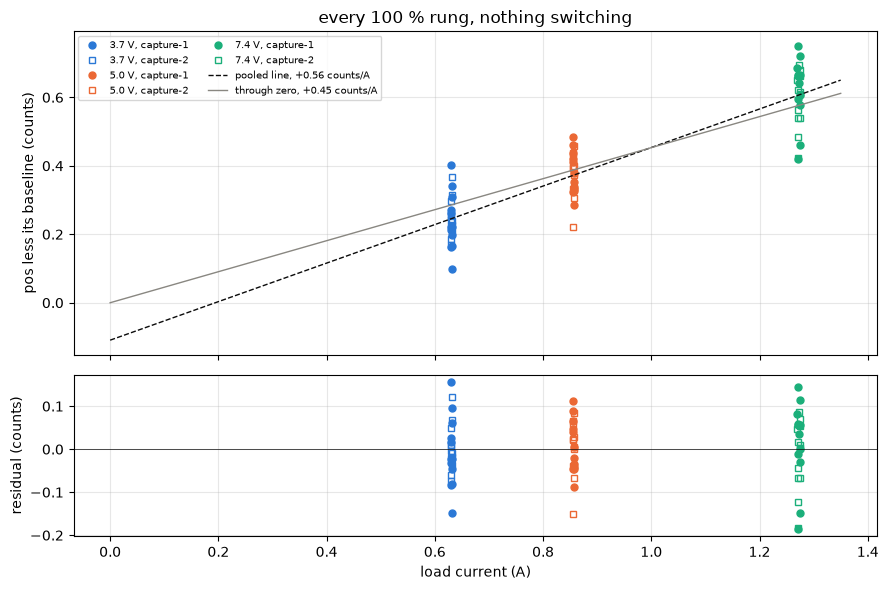

In [12]:
both = pd.concat([H1.assign(cap="capture-1"), H2.assign(cap="capture-2")])
both = both.reset_index(drop=True)
f = DC["pooled"]
resid = both["d_pos"] - (f["intercept"] + f["slope"] * both["i_load_a"])
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True,
                       gridspec_kw={"height_ratios": [2, 1]})
for (v, cap), g in both.groupby(["rail", "cap"]):
    first = cap == "capture-1"
    style = {"ls": "none", "color": RAIL_COLOR[v], "ms": 5,
             "marker": "o" if first else "s",
             "mfc": RAIL_COLOR[v] if first else "none"}
    ax[0].plot(g["i_load_a"], g["d_pos"], label=f"{v} V, {cap}", **style)
    ax[1].plot(g["i_load_a"], resid[g.index], **style)
xx = np.linspace(0, 1.35, 10)
ax[0].plot(xx, f["intercept"] + f["slope"] * xx, color=INK, ls="--",
           lw=1, label=f"pooled line, {f['slope']:+.2f} counts/A")
ax[0].plot(xx, f["b0"] * xx, color=MUTED, lw=1,
           label=f"through zero, {f['b0']:+.2f} counts/A")
ax[1].axhline(0, color=INK, lw=0.5)
ax[0].legend(fontsize=7, ncol=2)
figures.label(ax[0], y="pos less its baseline (counts)",
              title="every 100 % rung, nothing switching")
figures.label(ax[1], x="load current (A)", y="residual (counts)")
figures.finish(fig)

Both captures put the DC coupling at about half a count per amp. Capture-2 alone gives 0.531 +/- 0.042 counts/A with an intercept of -0.085 +/- 0.040 counts and 0.066 counts rms, and both captures pooled, 72 rungs, give 0.563 +/- 0.033 counts/A with an intercept of -0.109 +/- 0.032 counts. Through zero the slope is 0.446 +/- 0.012 on capture-2 and 0.453 +/- 0.010 pooled. The two directions give +0.49 +/- 0.06 and +0.57 +/- 0.05 counts/A on capture-2, the same sign and about the same size, which is what a drop in shared copper does. The slow and fast 100 % rungs at one rail differ by up to 0.12 counts where nothing differs but the run, so a rung mean carries a run-to-run floor of about 0.1 count. At rest `pos` does not move with the rail, -0.005 +/- 0.010 counts/V over the 18 baselines.

So the board couples +0.5 +/- 0.1 counts per amp of load current into `pos` at DC, the same sign in both directions, with high confidence.

### The locked-horn shift and the steps offset

The pooled line at 0.77 A is in the print above. Beside it, each capture's rungs in one direction against the other, every rail, decay and duty.

In [13]:
def direction_gap(R, column):
    # (+1) - (-1) of a column's group means, per decay, rail and duty
    w = R.groupby(["decay", "rail", "duty", "dir"])[column].mean()
    w = w.unstack("dir")
    return w[1] - w[-1]


DIR_GAP = {}
for name, R in (("capture-1", R1), ("capture-2", R2)):
    gap = direction_gap(R, "d_pos")
    DIR_GAP[name] = gap
    worst = gap.iloc[gap.abs().argmax()]
    print(f"{name}: pos (+1) - (-1) mean {gap.mean():+.3f}, sd "
          f"{gap.std():.3f}, largest {worst:+.3f}, n {len(gap)} groups")

capture-1: pos (+1) - (-1) mean -0.041, sd 0.052, largest -0.157, n 36 groups
capture-2: pos (+1) - (-1) mean -0.009, sd 0.066, largest -0.170, n 36 groups


At 0.77 A the pooled line gives +0.32 +/- 0.04 counts. The locked horn read 7.4 counts under its baseline in both directions at that current, at 100 % duty, so with no switching either. A third of a count of the opposite sign is not -7.4, so the board between the POS connector and the ADC is cleared for the locked-horn shift, with high confidence.

The bench found the cause in the lock itself. The rig's base printed with its mounting hole oversize, so the screw drops in rather than locating, the nut sits below the screw and does not seat, and the rotor was heard to click at each stall and each release during the locked captures. A horn that shifts under torque and settles back moves the pot by a few counts in a way that depends on the torque, which is what the locked laps read. The locked comparison was the pot during the press against the pot after torque-off, so it summed two motions, the lock giving under torque and the gear train's wind-up releasing through its backlash at torque-off, which moves the rest reading itself. Both act the same way in either direction, which is why most of the shift was common to both. With the board cleared to 0.3 counts at that current and the lock known to move, the -7.4 counts are mechanical, with high confidence.

The steps notebook's +23 counts/A on the -1 leg is not the board either. Here `pos` reads the same in both directions, (+1) - (-1) = -0.01 counts with an sd of 0.07 over 36 groups on capture-2. Its +2.6 to +4 count offsets at the -1 starts match the size of the onset transient further down at 20 to 40 %, a candidate reading with medium-low confidence.

### The partial-duty shifts

Below 100 % the bridge switches. Each rail, decay and duty as one group, three repeats and both directions, in both captures.

In [14]:
def groups(R):
    # per decay, rail and duty: the shifts' means and standard errors
    agg = {"n": ("d_pos", "size"), "i_load": ("i_load_a", "mean"),
           "d_pos": ("d_pos", "mean"), "d_pos_se": ("d_pos", se),
           "d_ntc": ("dc_ntc_raw", "mean"), "d_ntc_se": ("dc_ntc_raw", se),
           "d_ntc_err": ("dc_err_ntc_raw", "mean"),
           "d_vbus": ("d_vbus_raw", "mean"), "d_vbus_se": ("d_vbus_raw", se)}
    if "dc_vref_raw" in R:
        agg["d_vref"] = ("dc_vref_raw", "mean")
        agg["d_vref_se"] = ("dc_vref_raw", se)
    return R.groupby(["decay", "rail", "duty"]).agg(**agg).reset_index()


G1, G2 = groups(R1), groups(R2)
REPEAT = results.fit_line(G1["d_pos"], G2["d_pos"])
REPEAT["corr"] = np.corrcoef(G1["d_pos"], G2["d_pos"])[0, 1]
REPEAT["rms_diff"] = np.sqrt(((G2["d_pos"] - G1["d_pos"]) ** 2).mean())
NTC_REPEAT = results.fit_line(G1["d_ntc"], G2["d_ntc"])
NTC_REPEAT["corr"] = np.corrcoef(G1["d_ntc"], G2["d_ntc"])[0, 1]
TOP = G2["d_pos"].abs().idxmax()      # the largest group, capture-2
BY_DIR1 = R1.groupby(["decay", "rail", "duty", "dir"])["d_pos"].mean()
print(f"capture-2 on capture-1, {len(G1)} groups: slope "
      f"{REPEAT['slope']:.3f} +/- {REPEAT['slope_se']:.3f}, corr "
      f"{REPEAT['corr']:.3f}, rms difference {REPEAT['rms_diff']:.3f} "
      f"counts; NTC slope {NTC_REPEAT['slope']:.3f} +/- "
      f"{NTC_REPEAT['slope_se']:.3f}, corr {NTC_REPEAT['corr']:.3f}")
top = G2.loc[TOP]
print(f"largest group, capture-2: {top['d_pos']:+.2f} +/- "
      f"{top['d_pos_se']:.2f} counts at {top['decay']} {top['duty']} %, "
      f"{top['rail']} V; capture-1 {G1.loc[TOP, 'd_pos']:+.2f}")
print(f"capture-1 groups by direction from {BY_DIR1.min():+.2f} to "
      f"{BY_DIR1.max():+.2f} counts")

capture-2 on capture-1, 36 groups: slope 0.984 +/- 0.013, corr 0.997, rms difference 0.032 counts; NTC slope 0.938 +/- 0.025, corr 0.988
largest group, capture-2: +1.63 +/- 0.02 counts at fast 60 %, 7.4 V; capture-1 +1.68
capture-1 groups by direction from -0.16 to +1.69 counts


Every group's shift by duty in both decays, capture-1 filled and capture-2 open, and on the right capture-1's slow-decay groups against their load current, labeled by duty, with the pooled 100 % line.

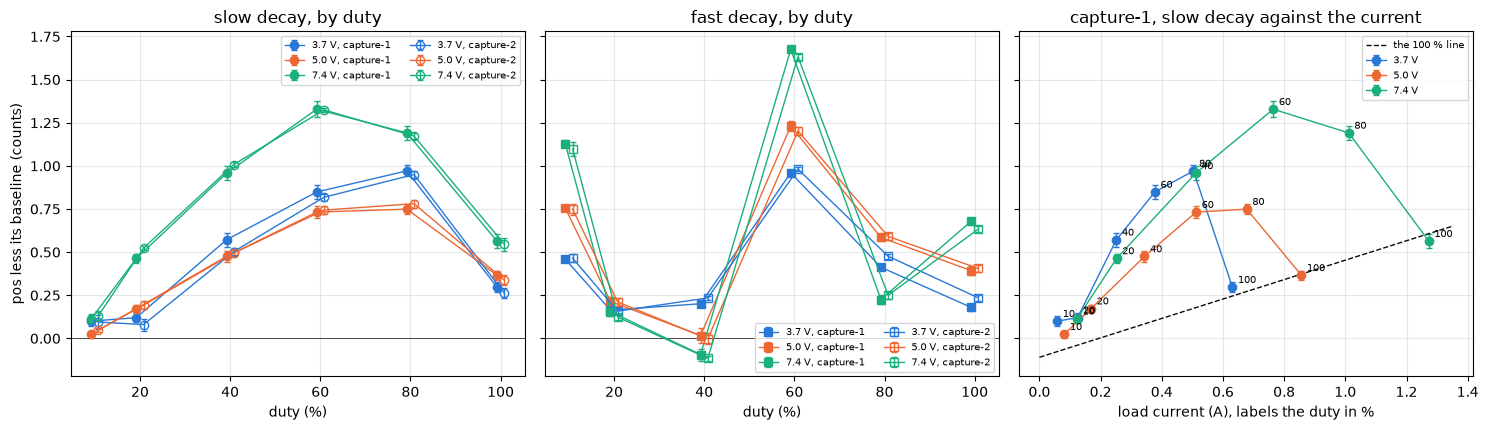

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for a, decay in zip(ax[:2], ("slow", "fast")):
    for cap, G, dx in (("capture-1", G1, -0.8), ("capture-2", G2, 0.8)):
        for v, g in G[G["decay"] == decay].groupby("rail"):
            c = RAIL_COLOR[v]
            a.errorbar(g["duty"] + dx, g["d_pos"], yerr=g["d_pos_se"],
                       color=c, marker=DECAY_MARKER[decay], capsize=2,
                       lw=1, mfc=c if cap == "capture-1" else "none",
                       label=f"{v} V, {cap}")
    a.axhline(0, color=INK, lw=0.5)
    figures.label(a, x="duty (%)", title=f"{decay} decay, by duty")
    a.legend(fontsize=7, ncol=2)
slow1 = G1[G1["decay"] == "slow"]
for v, g in slow1.groupby("rail"):
    ax[2].errorbar(g["i_load"], g["d_pos"], yerr=g["d_pos_se"], capsize=2,
                   color=RAIL_COLOR[v], marker="o", lw=1, label=f"{v} V")
    for _, r in g.iterrows():
        ax[2].annotate(f"{r['duty']}", (r["i_load"], r["d_pos"]), fontsize=7,
                       textcoords="offset points", xytext=(4, 3))
xx = np.linspace(0, 1.35, 10)
f = DC["pooled"]
ax[2].plot(xx, f["intercept"] + f["slope"] * xx, color=INK, ls="--",
           lw=1, label="the 100 % line")
ax[2].legend(fontsize=7)
figures.label(ax[0], y="pos less its baseline (counts)")
figures.label(ax[2], x="load current (A), labels the duty in %",
              title="capture-1, slow decay against the current")
figures.finish(fig)

The slow-decay groups at about one current on three rails, and each partial-duty group's excess over capture-1's 100 % line against the rail. At fast 10 to 40 % the load current is a few tens of milliamps at most, so the line there is about its intercept.

In [16]:
slow1 = G1[G1["decay"] == "slow"].set_index(["rail", "duty"])
for match in MATCHED:
    print(" | ".join(f"{v} V {d} %: {slow1.loc[(v, d), 'i_load']:.3f} A "
                     f"-> {slow1.loc[(v, d), 'd_pos']:+.2f} +/- "
                     f"{slow1.loc[(v, d), 'd_pos_se']:.2f}"
                     for v, d in match))
f1 = DC["capture-1"]
dc = f1["intercept"] + f1["slope"] * G1["i_load"].fillna(0.0)
G1["excess"] = G1["d_pos"] - dc
EXCESS = {}
for (decay, d), g in G1[G1["duty"] < 100].groupby(["decay", "duty"]):
    fe = results.fit_line(g["rail"], g["excess"])
    EXCESS[(decay, d)] = fe
    print(f"{decay} {d:3d} %: excess " +
          " ".join(f"{e:+.2f}" for e in g["excess"]) +
          f" at 3.7/5/7.4 V, {fe['slope']:+.3f} +/- {fe['slope_se']:.3f} "
          "counts/V")
fast10 = R1[(R1["decay"] == "fast") & (R1["duty"] == 10)]
crest = fast10.groupby("rail")["i_crest_nodrive_a"].mean() * 1e3
print("fast 10 % crest over the zero: " +
      ", ".join(f"{v} V {c:+.0f} mA" for v, c in crest.items()))

3.7 V 20 %: 0.125 A -> +0.12 +/- 0.03 | 5.0 V 10 %: 0.081 A -> +0.02 +/- 0.02 | 7.4 V 10 %: 0.123 A -> +0.11 +/- 0.03
3.7 V 40 %: 0.251 A -> +0.57 +/- 0.04 | 5.0 V 20 %: 0.169 A -> +0.17 +/- 0.02 | 7.4 V 20 %: 0.252 A -> +0.46 +/- 0.03
3.7 V 80 %: 0.503 A -> +0.97 +/- 0.03 | 5.0 V 60 %: 0.512 A -> +0.73 +/- 0.04 | 7.4 V 40 %: 0.510 A -> +0.96 +/- 0.04
3.7 V 100 %: 0.631 A -> +0.30 +/- 0.03 | 5.0 V 80 %: 0.678 A -> +0.75 +/- 0.03 | 7.4 V 60 %: 0.764 A -> +1.33 +/- 0.05
fast  10 %: excess +0.59 +0.89 +1.26 at 3.7/5/7.4 V, +0.177 +/- 0.018 counts/V
fast  20 %: excess +0.30 +0.35 +0.29 at 3.7/5/7.4 V, -0.005 +/- 0.016 counts/V
fast  40 %: excess +0.33 +0.15 +0.04 at 3.7/5/7.4 V, -0.075 +/- 0.025 counts/V
fast  60 %: excess +1.07 +1.33 +1.73 at 3.7/5/7.4 V, +0.177 +/- 0.008 counts/V
fast  80 %: excess +0.36 +0.46 -0.04 at 3.7/5/7.4 V, -0.120 +/- 0.073 counts/V
slow  10 %: excess +0.20 +0.11 +0.17 at 3.7/5/7.4 V, -0.002 +/- 0.025 counts/V
slow  20 %: excess +0.18 +0.21 +0.45 at 3.7/5/7.4 V, 

Inside a rung, whether the shift is a step or a drift, and what it does to the spread of the samples. Every window of every sweep is split into its frame pattern, the mean by row of the TEL frame, and the scatter about it. The same split serves the frame-pattern and noise sections below, so it runs over every channel of both captures.

In [17]:
def split(x, tick):
    # (mean, the frame pattern about the mean, its rms, the sd about it)
    by_row = pd.Series(x).groupby(tick % FRAME)
    pat = by_row.mean().to_numpy() - x.mean()
    resid = x - by_row.transform("mean").to_numpy()
    return x.mean(), pat, np.sqrt((pat ** 2).mean()), resid.std()


def windows(df, seg):
    # (duty, dir, seg, rows): the baseline as duty 0, then every rung
    out = [(0, 0, 0, tel.baseline(df))]
    for _, sr in seg[seg["seg"] > 0].iterrows():
        s = int(sr["seg"])
        out.append((duty_of(sr), int(sr["dir"]), s, settled(df, s)))
    return out

The split over every window and channel, and the 7.4 V samples of capture-1 kept for the histograms.

In [18]:
HIST_KEYS = [("fast", 60), ("fast", 10), ("slow", 60), ("slow", 100)]
rows, PATTERNS, HIST = [], {}, {}
for (cap, k), (df, meta, seg) in DATA.items():
    sw = SWEEPS[cap].set_index("k").loc[k]
    for duty, d, s, g in windows(df, seg):
        tick = g["tick"].to_numpy()
        for c in (RAW1 if cap == "capture-1" else RAW2):
            x = g[c].to_numpy(float)
            mean, pat, prms, rsd = split(x, tick)
            h = len(x) // 2
            half = x[h:].mean() - x[:h].mean() if duty else np.nan
            rows.append({"cap": cap, "k": k, "rail": sw["volts_set"],
                         "decay": sw["decay"], "duty": duty, "dir": d,
                         "seg": s, "ch": c, "mean": mean,
                         "sd": x.std(ddof=1), "frame_rms": prms,
                         "frame_pp": np.ptp(pat), "resid_sd": rsd,
                         "half_diff": half})
            PATTERNS[(cap, k, s, c)] = pat
        hk = ("base", 0) if duty == 0 else (sw["decay"], duty)
        if cap == "capture-1" and sw["volts_set"] == 7.4 and (
                duty == 0 or hk in HIST_KEYS):
            HIST.setdefault(hk, []).append(g["pos"].to_numpy())
W = pd.DataFrame(rows)
print(f"{len(W)} windows x channels, {W['k'].nunique()} sweeps per capture")

2808 windows x channels, 18 sweeps per capture


The second half of each rung's `pos` less its first half, by group in capture-1.

In [19]:
P1 = W[(W["cap"] == "capture-1") & (W["ch"] == "pos") & (W["duty"] > 0)]
halves = P1.groupby(["decay", "rail", "duty"])["half_diff"].agg(
    ["mean", se])
print(f"second half - first half: largest group mean "
      f"{halves['mean'].abs().max():.3f} counts, groups over 2 se "
      f"{(halves['mean'].abs() > 2 * halves['se']).sum()} of "
      f"{len(halves)}, sd over the {len(P1)} rungs "
      f"{P1['half_diff'].std():.3f}")

second half - first half: largest group mean 0.024 counts, groups over 2 se 3 of 36, sd over the 216 rungs 0.028


The `pos` codes of four 7.4 V rungs of capture-1, pooled over the repeats and both directions, against the 7.4 V baselines pooled.

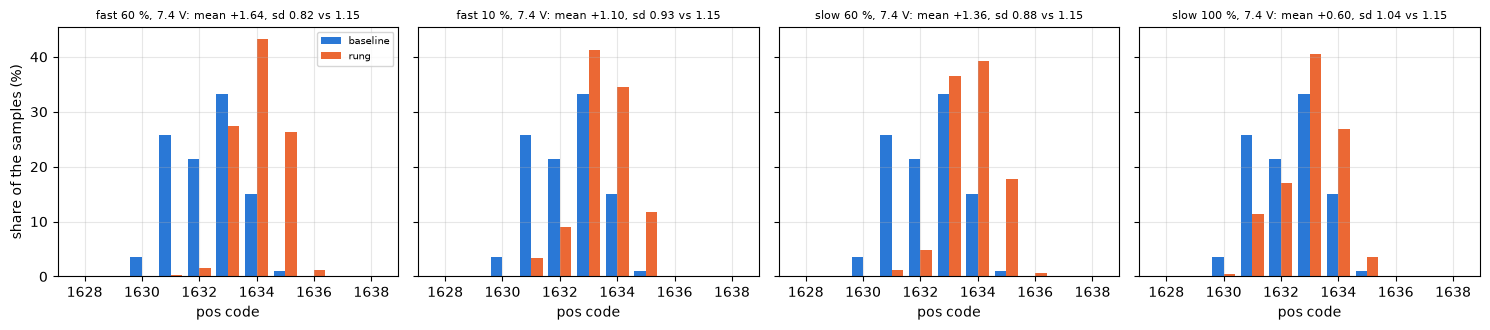

In [20]:
base_x = np.concatenate(HIST[("base", 0)])
base_share = np.array([(base_x == c).mean() for c in HIST_CODES]) * 100
fig, ax = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for a, key in zip(ax, HIST_KEYS):
    x = np.concatenate(HIST[key])
    share = np.array([(x == c).mean() for c in HIST_CODES]) * 100
    a.bar(HIST_CODES - 0.2, base_share, width=0.4, color=BLUE,
          label="baseline")
    a.bar(HIST_CODES + 0.2, share, width=0.4, color=ORANGE, label="rung")
    figures.label(a, x="pos code",
                  title=f"{key[0]} {key[1]} %, 7.4 V: mean "
                        f"{x.mean() - base_x.mean():+.2f}, sd {x.std():.2f}"
                        f" vs {base_x.std():.2f}")
    a.title.set_fontsize(8)
ax[0].legend(fontsize=7)
figures.label(ax[0], y="share of the samples (%)")
figures.finish(fig)

The partial-duty shifts repeat. Capture-2 against capture-1 over the 36 rail, decay and duty groups gives a slope of 0.984 +/- 0.013, a correlation of 0.997 and an rms difference of 0.032 counts. The largest group mean is +1.63 +/- 0.02 counts at fast 60 %, 7.4 V, where capture-1 read +1.68. Every group mean of capture-1, by direction, lies between -0.16 and +1.69 counts. The NTC's shifts repeat as well, a slope of 0.94 +/- 0.03 and a correlation of 0.99.

The shape depends on the decay. In slow decay the shift rises with the duty to 60 or 80 % and falls back at 100 %, +1.33 +/- 0.05 at 60 % on 7.4 V. At about one current the duty still matters. Near 0.63 to 0.76 A the shift is +0.30 at 100 %, +0.75 at 80 % and +1.33 at 60 %, so the slow-decay part is not the DC line. In fast decay the shift bumps at 10 % and at 60 % and sits about at zero at 40 %, and both bumps grow with the rail by +0.177 counts/V. At fast 10 % the current reaches zero every period, its crest over the zero is +2 to +8 mA, so the +0.46, +0.76 and +1.13 counts there are not an IR drop.

Inside a rung the shift is a step. The second half less the first half is at most 0.024 counts in any group, with an sd of 0.028 over 216 rungs. The bumps move the whole sample distribution and narrow it, as the histograms show at fast 60 % and slow 60 %. Code 1632 is under-filled in every window, the baselines included, a non-linearity of the converter that bends a mean in counts by a fraction of a count.

So the partial-duty shifts, up to +1.7 counts, repeat across captures to 0.03 counts, with high confidence, and they follow the duty and the decay, not the current. What they are comes up again in the edge section.

### The rung onset as a VDD dip

Each 100 % onset of capture-2 aligned on the drive's first row, the current 100 counts over its zero, each channel as a share of its baseline with the frame pattern taken off. Onsets whose stream opened after the edge are left out.

In [21]:
CH2 = ["pos", "vref_raw", "ntc_raw", "vbus_raw"]
ONSET_ROWS = 200                      # rows, 10 ms after the edge
TRACES2 = {}
for k, sw in SWEEPS["capture-2"].set_index("k").iterrows():
    df, meta, seg = DATA[("capture-2", int(k))]
    b = tel.baseline(df)
    zero = b["current_raw"].median()
    for s in FULL:
        g = df[df["seg"] == s].reset_index(drop=True)
        over = (g["current_raw"] - zero).to_numpy()
        i0 = int(np.flatnonzero(over > EDGE_COUNTS)[0])
        if i0 < 1:                    # the stream opened after the edge
            continue
        w = g.iloc[i0:i0 + ONSET_ROWS]
        level = g.iloc[SKIP:]
        for c in CH2:
            pat = pattern(b, c).reindex(w["tick"] % FRAME).to_numpy()
            y = (w[c].to_numpy(float) - pat) / b[c].mean() - 1
            rung = level[c].mean() / b[c].mean() - 1
            TRACES2.setdefault((sw["volts_set"], c), []).append((y, rung))
print({v: len(TRACES2[(v, "pos")]) for v in RAILS}, "onsets per rail")

{3.7: 11, 5.0: 11, 7.4: 11} onsets per rail


Per rail, each channel's peak share over the first 2 ms, the VDD dip from `vref_raw`, how long `vref_raw` stays over half its peak and until it stays within 0.1 % of the rung, and `pos`'s share less `vref_raw`'s after the peak.

In [22]:
def onset_row(v):
    out = {"rail": v, "n": len(TRACES2[(v, "pos")])}
    for c in CH2:
        Y = np.array([y for y, _ in TRACES2[(v, c)]])
        mean = Y[:, :PEAK_ROWS].mean(0)
        # the positive peak, and the rail's sag
        j = int(np.argmin(mean) if c == "vbus_raw" else np.argmax(mean))
        out[f"{c}_pct"] = Y[:, j].mean() * 100
        out[f"{c}_se"] = se(Y[:, j]) * 100
        out[f"{c}_row"] = j
    Y = np.array([y for y, _ in TRACES2[(v, "vref_raw")]])
    rung = np.mean([r for _, r in TRACES2[(v, "vref_raw")]])
    m = Y.mean(0)
    j = int(np.argmax(m[:PEAK_ROWS]))
    dips = VDD_MV * Y[:, j] / (1 + Y[:, j])
    out["dip_mv"] = VDD_MV * m[j] / (1 + m[j])
    out["dip_se"], out["dip_us"] = se(dips), j * US_PER_ROW
    above = np.flatnonzero(m >= m[j] / 2)
    out["half_us"] = (above.max() - above.min() + 1) * US_PER_ROW
    off = np.flatnonzero(np.abs(m - rung) > SETTLED_SHARE)
    out["settle_us"] = (off.max() + 1) * US_PER_ROW if len(off) else 0
    out["rung_pct"] = rung * 100
    P = np.array([y for y, _ in TRACES2[(v, "pos")]]).mean(0)
    out["tail_x1e3"] = (P - m)[10:PEAK_ROWS].mean() * 1e3
    out["tail_min_x1e3"] = (P - m)[10:PEAK_ROWS].min() * 1e3
    return out


ONSET = pd.DataFrame([onset_row(v) for v in RAILS])
ONSET["pos_of_vref"] = ONSET["pos_pct"] / ONSET["vref_raw_pct"]
ONSET["ntc_of_vref"] = ONSET["ntc_raw_pct"] / ONSET["vref_raw_pct"]

The shares table, the peaks in % of each channel's baseline.

In [23]:
show(ONSET[["rail", "n", "vref_raw_pct", "vref_raw_se", "vref_raw_row",
            "pos_pct", "pos_se", "pos_row", "ntc_raw_pct", "ntc_raw_se",
            "pos_of_vref", "ntc_of_vref"]], n=None)
show(ONSET[["rail", "dip_mv", "dip_se", "dip_us", "half_us", "settle_us",
            "rung_pct", "tail_x1e3", "tail_min_x1e3"]], n=None)
VDD_DC = {}
for v, g in H2.groupby("rail"):
    VDD_DC[v] = (g["d_vref_raw"].mean() / g["vref_raw_base"].mean()
                 * VDD_MV)
print("DC VDD drop on the 100 % rungs: " +
      ", ".join(f"{v} V {d:.1f} mV" for v, d in VDD_DC.items()))

,rail,n,vref_raw_pct,vref_raw_se,vref_raw_row,pos_pct,pos_se,pos_row,ntc_raw_pct,ntc_raw_se,pos_of_vref,ntc_of_vref
0,3.700,11,1.520,0.023,5,1.203,0.012,4,0.958,0.071,0.791,0.630
1,5.000,11,0.438,0.052,2,0.404,0.037,3,0.268,0.057,0.923,0.611
2,7.400,11,0.569,0.048,2,0.535,0.042,2,0.353,0.049,0.940,0.619


,rail,dip_mv,dip_se,dip_us,half_us,settle_us,rung_pct,tail_x1e3,tail_min_x1e3
0,3.700,49.311,0.733,250.000,500.000,800.000,0.112,-3.928,-7.121
1,5.000,14.355,1.708,100.000,200.000,450.000,0.048,-0.384,-0.925
2,7.400,18.645,1.547,100.000,150.000,450.000,0.038,-0.266,-0.940


DC VDD drop on the 100 % rungs: 3.7 V 3.7 mV, 5.0 V 1.7 mV, 7.4 V 1.3 mV


The three rails' onsets, `pos`, `vref_raw` and the NTC as shares of their baselines over the first 4 ms.

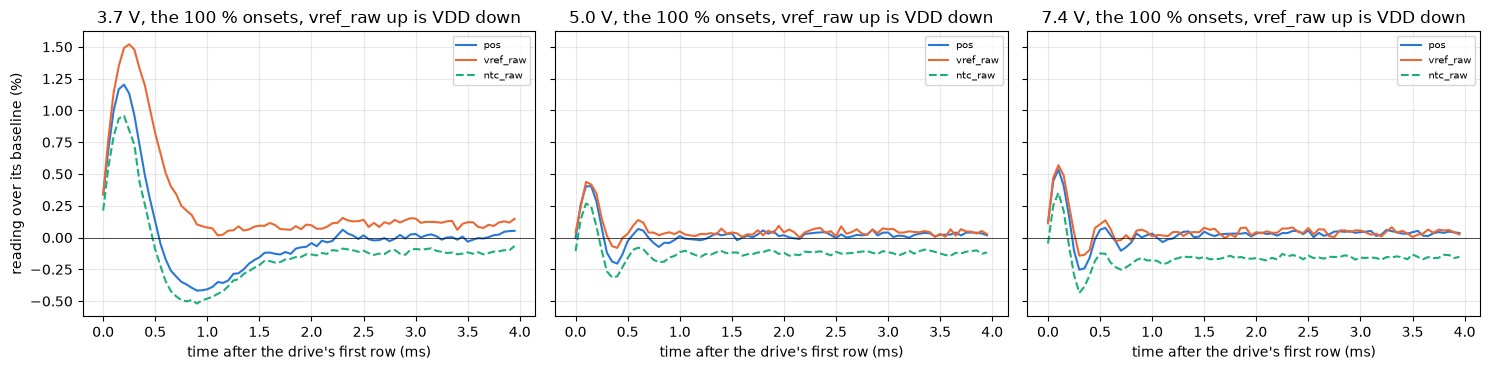

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
t = np.arange(ONSET_ROWS) / FS * 1e3
shown = [("pos", BLUE, "-"), ("vref_raw", ORANGE, "-"),
         ("ntc_raw", GREEN, "--")]
for a, v in zip(ax, RAILS):
    for c, color, ls in shown:
        Y = np.array([y for y, _ in TRACES2[(v, c)]]).mean(0)
        a.plot(t[:80], Y[:80] * 100, ls, color=color, lw=1.5, label=c)
    a.axhline(0, color=INK, lw=0.5)
    figures.label(a, x="time after the drive's first row (ms)",
                  title=f"{v} V, the 100 % onsets, vref_raw up is VDD down")
    a.legend(fontsize=7)
figures.label(ax[0], y="reading over its baseline (%)")
figures.finish(fig)

The same onsets in counts on capture-1's `pos`, aligned on the taps 100 counts apart, every slow-decay rung and the fast 100 % rungs, against a null of 40-row windows of the baselines.

In [25]:
PRE, POST = 6, 400          # rows before and after the edge
rows, TRACES1 = [], {}
for k, sw in SWEEPS["capture-1"].set_index("k").iterrows():
    df, meta, seg = DATA[("capture-1", int(k))]
    b = tel.baseline(df)
    pat = pattern(b, "pos")
    for _, sr in seg[seg["seg"] > 0].iterrows():
        d = duty_of(sr)
        if sw["decay"] == "fast" and d < 100:   # no tap edge to align on
            continue
        g = df[df["seg"] == sr["seg"]].reset_index(drop=True)
        apart = (g["vmotor_a"] - g["vmotor_b"]).abs().to_numpy()
        i0 = int(np.flatnonzero(apart > EDGE_COUNTS)[0])
        y = np.full(PRE + POST, np.nan)   # rows before the stream opened
        lo = max(i0 - PRE, 0)
        w = g.iloc[lo:i0 + POST]
        y[PRE - (i0 - lo):] = (w["pos"].to_numpy(float) - pat.reindex(
            w["tick"] % FRAME).to_numpy() - b["pos"].mean())
        key = (sw["decay"], sw["volts_set"], d)
        TRACES1.setdefault(key, []).append(y)
        z = y[PRE:]
        rows.append({"decay": sw["decay"], "rail": sw["volts_set"],
                     "duty": d, "edge_row": i0,
                     "peak": np.nanmax(z[:PEAK_ROWS]),
                     "peak_row": int(np.nanargmax(z[:PEAK_ROWS])),
                     "min_2ms": np.nanmin(z[:PEAK_ROWS])})
ONSET1 = pd.DataFrame(rows)
print(f"edge row {ONSET1['edge_row'].min()} to {ONSET1['edge_row'].max()}, "
      f"{(ONSET1['edge_row'] < 2).sum()} of {len(ONSET1)} rungs open with "
      "the drive already on")

edge row 0 to 9, 29 of 126 rungs open with the drive already on


The peaks by group, the 100 % rungs pooled over both decays, and the null.

In [26]:
by = ONSET1.groupby(["decay", "rail", "duty"])
show(by.agg(n=("peak", "size"), peak=("peak", "mean"), peak_se=("peak", se),
            peak_row=("peak_row", "median"), min_2ms=("min_2ms", "mean"))
     .reset_index(), n=None)
POS_PEAK = {}
for v, g in ONSET1[ONSET1["duty"] == 100].groupby("rail"):
    POS_PEAK[v] = (g["peak"].mean(), se(g["peak"]), len(g))
    print(f"100 % {v} V, both decays: peak {g['peak'].mean():+.1f} +/- "
          f"{se(g['peak']):.1f} counts, n {len(g)}")
null = []
for (cap, k), (df, meta, seg) in DATA.items():
    if cap != "capture-1":
        continue
    b = tel.baseline(df)
    z = (b["pos"].to_numpy(float) - pattern(b, "pos").reindex(
        b["tick"] % FRAME).to_numpy() - b["pos"].mean())
    for j in range(0, len(z) - PEAK_ROWS, 400):
        null.append((z[j:j + PEAK_ROWS].max(), z[j:j + PEAK_ROWS].min()))
null = np.array(null)
print(f"null, {len(null)} baseline windows: peak 99th percentile "
      f"{np.percentile(null[:, 0], 99):+.2f}, low 1st percentile "
      f"{np.percentile(null[:, 1], 1):+.2f} counts")

,decay,rail,duty,n,peak,peak_se,peak_row,min_2ms
0,fast,3.700,100,6,19.813,0.424,5.000,-7.401
1,fast,5.000,100,6,6.483,0.453,2.000,-2.943
2,fast,7.400,100,6,8.749,0.571,2.000,-4.216
3,slow,3.700,10,6,2.945,0.189,1.000,-1.992
4,slow,3.700,20,6,3.659,0.197,1.500,-1.944
5,slow,3.700,40,6,5.891,0.208,5.500,-2.684
6,slow,3.700,60,6,9.715,0.428,5.000,-4.102
7,slow,3.700,80,6,14.493,0.418,5.000,-5.041
8,slow,3.700,100,6,20.063,0.531,5.000,-7.006
9,slow,5.000,10,6,4.057,0.353,0.500,-3.055


100 % 3.7 V, both decays: peak +19.9 +/- 0.3 counts, n 12
100 % 5.0 V, both decays: peak +7.0 +/- 0.5 counts, n 12
100 % 7.4 V, both decays: peak +7.6 +/- 0.5 counts, n 12
null, 450 baseline windows: peak 99th percentile +2.11, low 1st percentile -2.22 counts


`pos` in counts over the first 3 ms, the 100 % rungs by rail on the left and slow decay at 3.7 V by duty on the right.

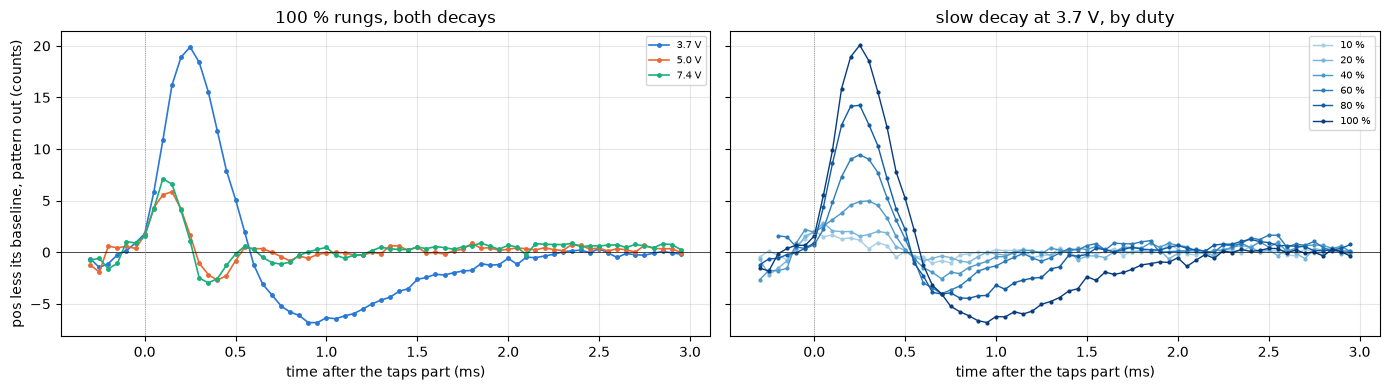

In [27]:
def row_mean(ys):
    # the mean over rungs row by row, a row no rung reached left empty
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        return np.nanmean(np.array(ys), 0)


fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
t = np.arange(-PRE, POST) / FS * 1e3
span = PRE + 60
for v in RAILS:
    ys = TRACES1[("slow", v, 100)] + TRACES1[("fast", v, 100)]
    ax[0].plot(t[:span], row_mean(ys)[:span], "o-",
               ms=2.5, lw=1.2, color=RAIL_COLOR[v], label=f"{v} V")
shades = figures.shades("Blues", len(DUTIES))
for color, d in zip(shades, DUTIES):
    ys = TRACES1[("slow", 3.7, d)]
    ax[1].plot(t[:span], row_mean(ys)[:span], "o-", ms=2,
               lw=1, color=color, label=f"{d} %")
for a, title in zip(ax, ["100 % rungs, both decays",
                         "slow decay at 3.7 V, by duty"]):
    a.axhline(0, color=INK, lw=0.5)
    a.axvline(0, **figures.EDGE_STYLE)
    figures.label(a, x="time after the taps part (ms)", title=title)
    a.legend(fontsize=7)
figures.label(ax[0], y="pos less its baseline, pattern out (counts)")
figures.finish(fig)

The onset is a VDD dip. At every rail `vref_raw` rises with `pos` and the NTC at the same rows, and `vref_raw` reads VDD itself. At 3.7 V it peaks at +1.52 +/- 0.02 % at row 5, a VDD dip of 49.3 +/- 0.7 mV 250 us after the edge, stays over half its peak for 500 us and is back within 0.1 % of the rung after 800 us. At 5 and 7.4 V the dip is 14.4 +/- 1.7 and 18.6 +/- 1.5 mV, over half its peak for 200 and 150 us, and settled after 450 us. `pos` carries 79 % of `vref_raw`'s share at 3.7 V and 92 to 94 % at 5 and 7.4 V, and the NTC 61 to 63 % at every rail. Both divider nodes have filters, and they follow part of the dip, so they hold most of their charge through it and read up by most of the dip's share.

At 3.7 V `vref_raw` settles high, +0.11 % of the rung, VDD 3.7 mV low. `pos` recovers through an undershoot, its share less `vref_raw`'s averaging -3.9 x 10^-3 over rows 10 to 40 and reaching -7.1 x 10^-3, which reads as the POS1 node relaxing toward the lower VDD over about 2 ms. The DC VDD drop on the 100 % rungs is 3.7, 1.7 and 1.3 mV at 3.7, 5 and 7.4 V, largest on the low rail where the regulator has the least headroom, a candidate.

In counts on capture-1's `pos` at 3.7 V, 100 %, that is +20 counts for about 0.5 ms, then about -7 recovering over 2 ms, and +7 for 0.15 to 0.2 ms at 5 and 7.4 V. Baseline windows of the same length reach +2.1 counts at their 99th percentile, so every 100 % onset is far outside the noise. In slow decay at 3.7 V the peak grows with the duty, +2.9, +3.7, +5.9, +9.7, +14.5 and +20.1 counts from 10 to 100 %. With high confidence the rung-onset transient is a VDD dip at the current's step.

### The frame pattern as VDD ripple

Every baseline's mean by row of the TEL frame, every channel of both captures, as counts and as a share of the channel's mean, and the scatter about the pattern.

In [28]:
rows, FPAT = [], {}
for (cap, k), (df, meta, seg) in DATA.items():
    b = tel.baseline(df)
    rail = SWEEPS[cap].set_index("k").loc[k, "volts_set"]
    for c in (RAW1 if cap == "capture-1" else RAW2):
        x = b[c].to_numpy(float)
        pat = b.groupby(b["tick"] % FRAME)[c].mean().to_numpy() - x.mean()
        resid = x - (pat[b["tick"].to_numpy() % FRAME] + x.mean())
        rows.append({"cap": cap, "k": k, "rail": rail, "ch": c,
                     "mean": x.mean(), "sd": x.std(), "pp": np.ptp(pat),
                     "rms": pat.std(), "resid_sd": resid.std(),
                     "share": pat.std() / x.mean()})
        FPAT[(cap, k, c)] = pat
FP = pd.DataFrame(rows)
summary = FP.groupby(["cap", "ch"], sort=False).agg(
    mean=("mean", "mean"), pp=("pp", "mean"), pp_se=("pp", se),
    rms=("rms", "mean"), share_x1e4=("share", "mean"),
    share_se_x1e4=("share", se), sd=("sd", "mean"),
    resid_sd=("resid_sd", "mean")).reset_index()
summary[["share_x1e4", "share_se_x1e4"]] *= 1e4
show(summary, n=None)

,cap,ch,mean,pp,pp_se,rms,share_x1e4,share_se_x1e4,sd,resid_sd
0,capture-1,pos,1632.338,3.123,0.029,0.916,5.609,0.060,1.127,0.656
1,capture-1,current_raw,1206.949,0.921,0.030,0.255,2.113,0.060,0.996,0.962
2,capture-1,vmotor_a,772.060,1.157,0.023,0.329,4.266,0.077,0.626,0.532
3,capture-1,vmotor_b,773.506,0.984,0.011,0.282,3.646,0.044,0.600,0.530
4,capture-1,vbus_raw,1331.383,1.829,0.155,0.516,3.770,0.112,1.260,1.146
5,capture-1,ntc_raw,1977.957,3.104,0.111,0.873,4.413,0.164,1.037,0.558
6,capture-2,pos,1632.421,2.927,0.035,0.855,5.240,0.069,1.084,0.666
7,capture-2,vref_raw,1491.124,2.269,0.049,0.633,4.248,0.099,1.292,1.126
8,capture-2,vbus_raw,1331.190,1.739,0.153,0.494,3.597,0.112,1.250,1.144
9,capture-2,ntc_raw,2010.223,2.873,0.069,0.805,4.008,0.105,0.970,0.541


On capture-2, each channel's share over `vref_raw`'s share sweep by sweep, how well each pattern follows `vref_raw`'s, the ripple on VDD and the pot floor with and without the pattern.

In [29]:
c2 = FP[FP["cap"] == "capture-2"].pivot_table(index="k", columns="ch",
                                              values="share")
OVER_VREF = {c: c2[c] / c2["vref_raw"] for c in ("pos", "ntc_raw", "vbus_raw")}
for c, r in OVER_VREF.items():
    print(f"{c} share over vref's: {r.mean():.3f} +/- {se(r):.3f}")
K2 = SWEEPS["capture-2"]["k"]
CORR = {c: np.array([np.corrcoef(FPAT[("capture-2", k, "vref_raw")],
                                 FPAT[("capture-2", k, c)])[0, 1]
                     for k in K2]) for c in ("pos", "ntc_raw", "vbus_raw")}
for c, cc in CORR.items():
    print(f"corr(vref pattern, {c} pattern): {cc.mean():+.3f} "
          f"(lowest {cc.min():+.3f}, n {len(cc)})")
v = FP[(FP["cap"] == "capture-2") & (FP["ch"] == "vref_raw")]
RIPPLE = {"pp": VDD_MV * v["pp"].mean() / v["mean"].mean(),
          "pp_se": VDD_MV * se(v["pp"]) / v["mean"].mean(),
          "rms": VDD_MV * v["rms"].mean() / v["mean"].mean()}
print(f"VDD ripple at the frame rate: {RIPPLE['pp']:.2f} mV pp, "
      f"{RIPPLE['rms']:.2f} mV rms, n {len(v)}")
FLOOR = {}
for cap in CAPTURES:
    p = FP[(FP["cap"] == cap) & (FP["ch"] == "pos")]
    FLOOR[cap] = p
    print(f"pos floor {cap}: sd {p['sd'].mean():.3f} +/- {se(p['sd']):.3f}, "
          f"pattern out {p['resid_sd'].mean():.3f} +/- "
          f"{se(p['resid_sd']):.3f} counts")

pos share over vref's: 1.239 +/- 0.015
ntc_raw share over vref's: 0.947 +/- 0.023
vbus_raw share over vref's: 0.845 +/- 0.012
corr(vref pattern, pos pattern): +0.976 (lowest +0.963, n 18)
corr(vref pattern, ntc_raw pattern): +0.970 (lowest +0.945, n 18)
corr(vref pattern, vbus_raw pattern): +0.969 (lowest +0.945, n 18)
VDD ripple at the frame rate: 5.01 mV pp, 1.40 mV rms, n 18
pos floor capture-1: sd 1.127 +/- 0.008, pattern out 0.656 +/- 0.001 counts
pos floor capture-2: sd 1.084 +/- 0.009, pattern out 0.666 +/- 0.002 counts


Whether the pattern holds its phase from sweep to sweep, and its size under drive, each rung's own pattern, both captures, the rails and directions pooled per decay and duty.

In [30]:
k74 = SWEEPS["capture-1"].query("volts_set == 7.4")["k"]
P0 = np.array([PATTERNS[("capture-1", k, 0, "pos")] for k in k74])
cc = np.corrcoef(P0)[np.triu_indices(len(P0), 1)]
print(f"capture-1 7.4 V baseline pos patterns, pairwise correlation "
      f"{cc.min():.3f} to {cc.max():.3f}")
DRIVE_PP = {}
for c in ("pos", "vref_raw"):
    g = W[(W["ch"] == c) & (W["duty"] > 0)]
    pp = g.groupby(["decay", "duty"])["frame_pp"].mean()   # pooled
    rest = W[(W["ch"] == c) & (W["duty"] == 0)]["frame_pp"]
    DRIVE_PP[c] = (pp.min(), pp.max(), rest.mean(), pp.mean())
    print(f"{c} pattern pp under drive, group means {pp.min():.2f} to "
          f"{pp.max():.2f} counts, at rest {rest.mean():.2f}")

capture-1 7.4 V baseline pos patterns, pairwise correlation 0.993 to 0.999
pos pattern pp under drive, group means 2.43 to 2.95 counts, at rest 3.02
vref_raw pattern pp under drive, group means 2.03 to 2.34 counts, at rest 2.27


The mean pattern over capture-2's 18 baselines, each channel as a share of its mean.

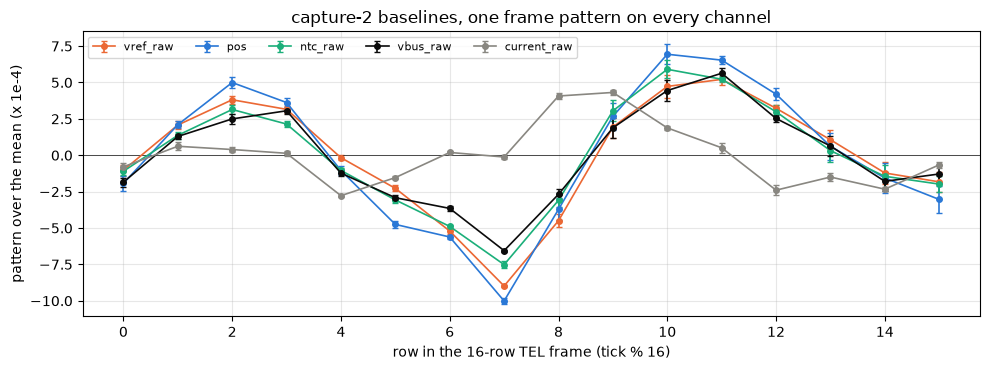

In [31]:
fig, ax = plt.subplots(figsize=(10, 3.8))
rows16 = np.arange(FRAME)
for c, color in (("vref_raw", ORANGE), ("pos", BLUE), ("ntc_raw", GREEN),
                 ("vbus_raw", INK), ("current_raw", MUTED)):
    share = np.array([FPAT[("capture-2", k, c)] / FP[
        (FP["cap"] == "capture-2") & (FP["k"] == k) & (FP["ch"] == c)
    ]["mean"].iloc[0] for k in K2]) * 1e4
    ax.errorbar(rows16, share.mean(0), yerr=share.std(0, ddof=1)
                / np.sqrt(len(share)), color=color, marker="o", ms=4,
                capsize=2, lw=1.2, label=c)
ax.axhline(0, color=INK, lw=0.5)
ax.legend(fontsize=8, ncol=5)
figures.label(ax, x="row in the 16-row TEL frame (tick % 16)",
              y="pattern over the mean (x 1e-4)",
              title="capture-2 baselines, one frame pattern on every "
                    "channel")
figures.finish(fig)

The frame pattern is a ripple on VDD. It repeats every 8 rows, 2.5 kHz, locked to the TEL frame, with the same phase in every sweep, and `vref_raw` reads it as 5.0 mV peak to peak, 1.40 mV rms, on VDD. The patterns of `pos`, the NTC and the rail tap follow `vref_raw`'s with correlations of +0.976, +0.970 and +0.969. As a share of each channel's mean the pattern is 4.25 +/- 0.10 x 10^-4 rms on `vref_raw`, 4.01 on the NTC, 4.10 to 4.27 on the taps, 3.60 on the rail, 2.18 on the current and 5.24 +/- 0.07 on `pos`. Over `vref_raw`'s share the NTC carries 0.947 +/- 0.023, the rail 0.845 +/- 0.012 and `pos` 1.239 +/- 0.015. So VDD explains the whole pattern on the NTC and the taps and about 80 % of `pos`'s, and `pos` carries 24 +/- 2 % more. Under drive the pattern keeps its size, 2.4 to 2.9 counts peak to peak on `pos` per decay and duty against 3.0 at rest, and 2.0 to 2.3 on `vref_raw` against 2.3 at rest, so the 3V3 ripple does not change with the bridge.

The pattern sets the pot's floor. At rest `pos` scatters by 1.127 counts on capture-1 and 1.084 on capture-2, and with the pattern taken out by 0.656 and 0.666. With high confidence the frame-rate pattern is VDD ripple, and it raises the floor of `pos` from about 0.66 to about 1.1 counts rms.

### Sample noise under drive

Each rung's sd over rows 200 to 6000 with its own frame pattern taken out, and the same for every baseline, both captures, the directions and rails pooled per decay and duty.

In [32]:
CH_NAME = {"pos": "pos", "ntc_raw": "ntc", "vref_raw": "vref",
           "vbus_raw": "rail", "current_raw": "shunt", "vmotor_a": "taps",
           "vmotor_b": "taps"}
W["name"] = W["ch"].map(CH_NAME)
REST_N = W[W["duty"] == 0]
DRIVE_N = W[W["duty"] > 0]
rows = []
for name in ("pos", "ntc", "vref", "rail", "shunt", "taps"):
    r = REST_N[REST_N["name"] == name]
    d = DRIVE_N[DRIVE_N["name"] == name]
    slow = d[d["decay"] == "slow"]
    rows.append({"channel": name, "rest": r["resid_sd"].mean(),
                 "rest_se": se(r["resid_sd"]), "rest_n": len(r),
                 "drive": d["resid_sd"].mean(), "drive_se": se(d["resid_sd"]),
                 "drive_n": len(d), "lo": d["resid_sd"].min(),
                 "hi": d["resid_sd"].max(), "slow": slow["resid_sd"].mean(),
                 "rest_raw": r["sd"].mean(), "drive_raw": d["sd"].mean()})
NOISE = pd.DataFrame(rows).set_index("channel")
show(NOISE.reset_index(), n=None)

,channel,rest,rest_se,rest_n,drive,drive_se,drive_n,lo,hi,slow,rest_raw,drive_raw
0,pos,0.661,0.001,36,0.630,0.002,432,0.507,0.699,0.628,1.105,1.003
1,ntc,0.550,0.008,36,0.549,0.002,432,0.489,0.763,0.541,1.004,0.961
2,vref,1.126,0.020,18,1.087,0.005,216,0.978,1.332,1.074,1.292,1.243
3,rail,1.145,0.040,36,1.185,0.013,432,0.762,2.219,1.214,1.255,1.291
4,shunt,0.962,0.005,36,1.213,0.012,432,0.861,2.088,1.249,0.997,1.283
5,taps,0.536,0.001,54,0.953,0.035,648,0.000,8.593,0.863,0.620,1.075


Where the drive's noise moves, each channel's group means by decay and duty.

In [33]:
NOISE_BY = DRIVE_N.groupby(["name", "decay", "duty"])["resid_sd"].mean()
table = NOISE_BY.unstack(["decay", "duty"]).round(2)
show(table.reset_index(), n=None)
for c in ("vmotor_a", "vmotor_b"):
    g = DRIVE_N[(DRIVE_N["ch"] == c) & (DRIVE_N["decay"] == "fast")
                & (DRIVE_N["duty"] == 40)]
    print(f"{c} at fast 40 %: {g['resid_sd'].mean():.2f} counts")
p60 = DRIVE_N[(DRIVE_N["name"] == "pos") & (DRIVE_N["duty"] == 60)]
p60 = p60.groupby(["decay", "cap", "rail"])["resid_sd"].mean()
for decay in ("fast", "slow"):
    print(f"pos at {decay} 60 %, per capture and rail "
          f"{p60[decay].min():.2f} to {p60[decay].max():.2f} counts")

decay   name  fast                                slow                    \
duty            10    20    40    60    80   100    10    20    40    60   
0        ntc 0.550 0.550 0.550 0.560 0.570 0.550 0.540 0.540 0.540 0.540   
1        pos 0.610 0.660 0.660 0.560 0.650 0.660 0.660 0.650 0.620 0.590   
2       rail 1.100 1.120 1.140 1.130 1.190 1.260 1.170 1.130 1.340 1.190   
3      shunt 1.100 1.120 1.100 1.200 1.160 1.380 0.990 1.020 1.400 1.450   
4       taps 0.520 0.560 2.370 0.820 1.100 0.880 0.900 0.880 0.830 0.850   
5       vref 1.120 1.100 1.080 1.100 1.100 1.080 1.140 1.060 1.050 1.080   

decay              
duty     80   100  
0     0.540 0.550  
1     0.590 0.660  
2     1.220 1.230  
3     1.240 1.390  
4     0.820 0.890  
5     1.050 1.070

vmotor_a at fast 40 %: 2.52 counts
vmotor_b at fast 40 %: 2.07 counts
pos at fast 60 %, per capture and rail 0.52 to 0.58 counts
pos at slow 60 %, per capture and rail 0.54 to 0.63 counts


`pos`'s sd with the pattern out, every rung against its duty in both decays, with the rest as the reference.

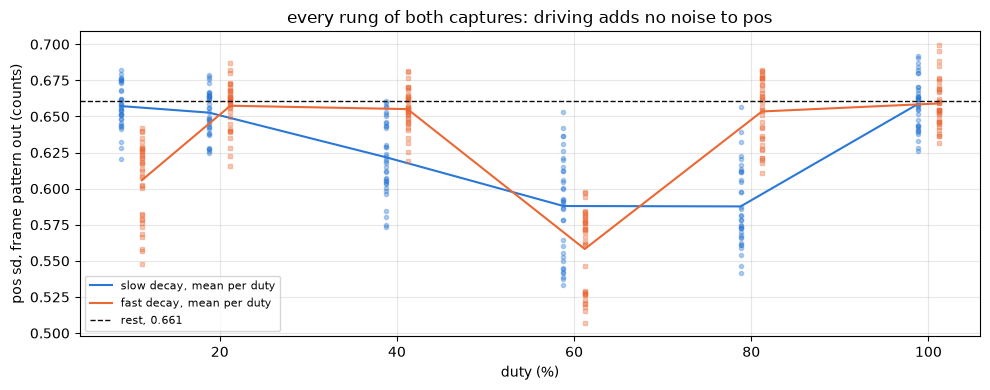

In [34]:
fig, ax = plt.subplots(figsize=(10, 4))
pos_drive = DRIVE_N[DRIVE_N["name"] == "pos"]
for decay, dx in (("slow", -1.2), ("fast", 1.2)):
    g = pos_drive[pos_drive["decay"] == decay]
    color = BLUE if decay == "slow" else ORANGE
    ax.plot(g["duty"] + dx, g["resid_sd"], DECAY_MARKER[decay], ms=3,
            alpha=0.35, color=color)
    m = g.groupby("duty")["resid_sd"].mean()
    ax.plot(m.index + dx, m.values, "-", color=color, lw=1.5,
            label=f"{decay} decay, mean per duty")
rest = NOISE.loc["pos", "rest"]
ax.axhline(rest, color=INK, lw=1, ls="--", label=f"rest, {rest:.3f}")
ax.legend(fontsize=8)
figures.label(ax, x="duty (%)", y="pos sd, frame pattern out (counts)",
              title="every rung of both captures: driving adds no noise "
                    "to pos")
figures.finish(fig)

Driving adds no noise to `pos`. With the pattern out it scatters by 0.661 +/- 0.001 counts at rest over 36 baselines and by 0.630 +/- 0.002 under drive over 432 rungs, 0.51 to 0.70 over every rail, decay, duty and direction. The 60 % rungs are a little quieter, 0.52 to 0.58 at fast 60 %, the same rungs that carry the largest partial-duty shifts. Raw, with the pattern in, the sd is 1.11 at rest and 1.00 under drive. The NTC reads 0.55 at rest and 0.55 under drive and `vref_raw` 1.13 against 1.09, unchanged. The rail tap goes from 1.14 to 1.19 and the shunt from 0.96 to 1.21, and the taps from 0.53 to about 0.9 under slow decay and 2.1 to 2.5 at fast 40 %, where the diode return ends inside their aperture. Those are switched nodes, and the extra is their signal's own ripple and the edges they straddle, not the converter.

So the bridge's switching adds nothing to the noise of the three high-impedance sense channels, `pos`, the NTC and `vref_raw`, and only the channels on switched nodes get noisier, by their signal's ripple. For stage 3 the `pos` sample variance under drive is the rest value, 0.63 to 0.66 counts with the pattern out and 1.0 to 1.1 raw.

### Edge proximity

Whether the partial-duty shifts follow VDD as `vref_raw` reads it. A held divider node reads a VDD move as $n_0 \, \Delta n_\mathrm{ref} / n_\mathrm{ref,0}$, so each capture-2 rung's `pos` shift against that prediction, and `pos` scaled row by row by `vref_raw`, the correction a firmware could run.

In [35]:
R2["pred"] = R2["pos_base"] * R2["dc_vref_raw"] / R2["vref_raw_base"]
VREF_PRED = results.fit_line(R2["pred"], R2["d_pos"])
VREF_PRED["corr"] = np.corrcoef(R2["pred"], R2["d_pos"])[0, 1]
print(f"pos shift on the vref prediction, {VREF_PRED['n']} rungs: slope "
      f"{VREF_PRED['slope']:+.3f} +/- {VREF_PRED['slope_se']:.3f}, corr "
      f"{VREF_PRED['corr']:+.3f}")
rows = []
for k in SWEEPS["capture-2"]["k"]:
    df, meta, seg = DATA[("capture-2", int(k))]
    b = tel.baseline(df)
    p0, v0 = b["pos"].mean(), b["vref_raw"].mean()
    for s in range(1, 13):
        g = settled(df, s)
        scaled = g["pos"] * v0 / g["vref_raw"]
        rows.append({"raw": g["pos"].mean() - p0,
                     "scaled": scaled.mean() - p0})
Q = pd.DataFrame(rows)
SCALED_RMS = {c: np.sqrt((Q[c] ** 2).mean()) for c in ("raw", "scaled")}
print(f"rung shift rms over {len(Q)} rungs: raw {SCALED_RMS['raw']:.2f}, "
      f"scaled by vref {SCALED_RMS['scaled']:.2f} counts")

pos shift on the vref prediction, 216 rungs: slope -0.001 +/- 0.008, corr -0.012


rung shift rms over 216 rungs: raw 0.68, scaled by vref 3.70 counts


Each channel's shift by direction on capture-2, three repeats each, and the two directions' difference.

In [36]:
D2 = R2.groupby(["decay", "rail", "duty", "dir"]).agg(
    d_pos=("d_pos", "mean"), d_pos_se=("d_pos", se),
    d_vref=("dc_vref_raw", "mean"), d_vref_se=("dc_vref_raw", se),
    d_ntc=("dc_ntc_raw", "mean"), d_ntc_se=("dc_ntc_raw", se)).reset_index()
wide = D2.pivot_table(index=["decay", "rail", "duty"], columns="dir",
                      values=["d_pos", "d_vref", "d_ntc"])
show(wide.round(2).reset_index(), n=None)
for c in ("d_pos", "d_ntc", "d_vref"):
    gap = wide[(c, 1)] - wide[(c, -1)]
    i = gap.abs().argmax()
    print(f"{c}: (+1) - (-1) mean {gap.mean():+.2f}, sd {gap.std():.2f}, "
          f"largest {gap.iloc[i]:+.2f} at {gap.index[i]}")

decay  rail duty  d_ntc         d_pos        d_vref       
dir                      -1      1     -1      1     -1      1
0    fast 3.700   10  0.020 -0.010  0.510  0.420  0.670 -0.570
1    fast 3.700   20  0.080 -0.030  0.130  0.190  0.130  1.190
2    fast 3.700   40  0.050 -0.120  0.230  0.240  1.790 -4.480
3    fast 3.700   60 -0.120 -0.350  0.980  0.980 -1.520  1.820
4    fast 3.700   80 -2.140 -2.430  0.500  0.450 -2.080  0.830
5    fast 3.700  100  0.280  0.030  0.250  0.220  1.800  1.720
6    fast 5.000   10 -0.070 -0.020  0.800  0.700  0.770 -0.720
7    fast 5.000   20 -0.040 -0.080  0.230  0.190  0.120  0.700
8    fast 5.000   40 -0.290 -0.230  0.020 -0.020  1.610 -7.930
9    fast 5.000   60 -0.520 -0.470  1.200  1.200 -2.230  1.840
10   fast 5.000   80 -2.310 -2.400  0.600  0.580 -3.210  1.070
11   fast 5.000  100 -0.120 -0.100  0.420  0.390  0.870  0.760
12   fast 7.400   10 -0.010 -0.010  1.180  1.010  1.410 -1.270
13   fast 7.400   20 -0.030 -0.010  0.130  0.110 -0.060  0.490
14   fast 7.400   40 -0.320 -0.270 -0.100 -0.130  1.620 -7.650
15   fast 7.400   60 -0.930 -0.850  1.620  1.650 -3.740  3.080
16   fast 7.400   80 -3.700 -3.880  0.220  0.280 -5.560  1.040
17   fast 7.400  100  0.060  0.140  0.610  0.660  0.370  0.630
18   slow 3.700   10  0.200  0.100  0.170  0.020  8.280  0.100
19   slow 3.700   20  0.400  0.310  0.130  0.030  1.940  0.420
20   slow 3.700   40  1.110  1.000  0.500  0.510  2.390  1.120
21   slow 3.700   60  1.450  1.290  0.800  0.840  0.890  1.540
22   slow 3.700   80  1.270  1.140  0.920  0.980  2.270  1.960
23   slow 3.700  100  0.080  0.070  0.210  0.310  1.630  1.650
24   slow 5.000   10  0.300  0.130  0.080  0.020 11.410  0.220
25   slow 5.000   20  0.480  0.340  0.210  0.180  2.510  0.460
26   slow 5.000   40  1.050  0.880  0.490  0.500  2.790  0.920
27   slow 5.000   60  1.200  0.970  0.720  0.770 -0.290  1.180
28   slow 5.000   80  0.960  0.700  0.770  0.790  1.580  1.280
29   slow 5.000  100  0.300  0.050  0.320  0.360  0.520  0.630
30   slow 7.400   10  0.550  0.210  0.190  0.080 17.750  0.240
31   slow 7.400   20  1.000  0.700  0.540  0.500  3.780  0.940
32   slow 7.400   40  1.890  1.610  0.980  1.030  3.800  1.560
33   slow 7.400   60  2.060  1.800  1.310  1.330 -0.190  1.840
34   slow 7.400   80  1.570  1.240  1.170  1.180  2.410  1.620
35   slow 7.400  100  0.460  0.420  0.480  0.610  0.510  0.810

d_pos: (+1) - (-1) mean -0.01, sd 0.07, largest -0.17 at ('fast', np.float64(7.4), np.int64(10))
d_ntc: (+1) - (-1) mean -0.12, sd 0.13, largest -0.35 at ('slow', np.float64(7.4), np.int64(10))
d_vref: (+1) - (-1) mean -1.27, sd 4.92, largest -17.51 at ('slow', np.float64(7.4), np.int64(10))


The crest scan's slot apertures in ticks after the crest, from sample-timing's shunt and high-tap slots, the 52-tick slot pitch and the reference's longer slot, and the fast return's length from bridge-states.

In [37]:
st = TIMING["crest_sample_ticks"]
PITCH = st["high_tap"]["value"] - st["shunt"]["value"]   # one slot, ticks
APERTURE = 27               # ticks, a 13.5-cycle sample at 2 ticks a cycle
VREF_SLOT = 2 * (54 - 26)   # ticks, the reference's 41.5 + 12.5 cycles
VREF_APERTURE = 83          # ticks, the reference's longer sample
PERIOD = 2 * BOARD.pwm_arr  # ticks, one PWM period
DIODES_V = 1.5              # V, two body diodes at a small return
RET_RAIL = 5.0              # V, the rail bridge-states timed the return on
POS_CLOSE = st["shunt"]["value"] + 3 * PITCH
VREF_CLOSE = POS_CLOSE + VREF_SLOT + PITCH
SLOTS = {"pos": (POS_CLOSE - APERTURE, POS_CLOSE),
         "vref": (VREF_CLOSE - VREF_APERTURE, VREF_CLOSE),
         "vbus": (VREF_CLOSE + PITCH - APERTURE, VREF_CLOSE + PITCH),
         "ntc": (VREF_CLOSE + 2 * PITCH - APERTURE, VREF_CLOSE + 2 * PITCH)}
FAST = S.fast_edge_lags()
ret = BRIDGE["return_us"]
d_ret = np.array([25, 40])
t_ret = np.array([ret["ra_25"]["value"], ret["ra_40"]["value"]])
K_RET = (d_ret * t_ret).sum() / (d_ret * d_ret).sum()   # us per % duty
print("slots (open, close):",
      {k: (round(a), round(b)) for k, (a, b) in SLOTS.items()})
print(f"return {K_RET:.3f} us per % duty at {RET_RAIL} V")

slots (open, close): {'pos': (160, 187), 'vref': (212, 295), 'vbus': (320, 347), 'ntc': (372, 399)}
return 0.330 us per % duty at 5.0 V


Every edge of a rung in ticks after the crest, and for each slot the nearest edge before it closes.

In [38]:
def edges(decay, rail, d):
    # [(name, ticks after the crest)] of a rung's edges
    if d == 100:
        return []
    if decay == "slow":
        on, off, _, _ = S.edge_lags_at(rail)
        return [("ON", -1200 * d / 100 + on), ("OFF", 1200 * d / 100 + off)]
    out = [("ON", 1200 * (1 - d / 100) + FAST["on"]),
           ("OFF", -1200 * (1 - d / 100) + FAST["off"])]
    if d < 50:      # the return ends before the next window
        t = (K_RET * d * (rail / (rail + DIODES_V))
             / (RET_RAIL / (RET_RAIL + DIODES_V)))
        out.append(("RET", -1200 * (1 - d / 100) + FAST["off"] + t * 48))
    return out


rows = []
for decay in ("slow", "fast"):
    for rail in RAILS:
        for d in DUTIES:
            E = edges(decay, rail, d)
            r = {"decay": decay, "rail": rail, "duty": d}
            for ch, (o, c) in SLOTS.items():
                if not E:
                    r[ch + "_lag"], r[ch + "_edge"] = np.nan, ""
                    continue
                lag, name = min(((c - t) % PERIOD, n) for n, t in E)
                r[ch + "_lag"], r[ch + "_edge"] = lag, name
            rows.append(r)
EDGES = pd.DataFrame(rows)

The edges table, each slot's lag after its nearest edge beside the shifts, `pos` less the DC line through zero, `vref_raw` by direction and the NTC.

In [39]:
DC_SLOPE = round(DC["pooled"]["b0"], 2)   # counts/A, as the note rounds it
G2["pos_x"] = G2["d_pos"] - DC_SLOPE * G2["i_load"].fillna(0)
vref_dir = D2.pivot_table(index=["decay", "rail", "duty"], columns="dir",
                          values="d_vref").reset_index()
vref_dir = vref_dir.rename(columns={-1: "vref_m", 1: "vref_p"})
EDGES = EDGES.merge(G2[["decay", "rail", "duty", "pos_x", "d_ntc"]],
                    on=["decay", "rail", "duty"])
EDGES = EDGES.merge(vref_dir, on=["decay", "rail", "duty"])
show(EDGES[["decay", "rail", "duty", "pos_lag", "pos_edge", "pos_x",
            "vref_lag", "vref_edge", "vref_m", "vref_p", "ntc_lag",
            "ntc_edge", "d_ntc"]].round(2), n=None)

,decay,rail,duty,pos_lag,pos_edge,pos_x,vref_lag,vref_edge,vref_m,vref_p,ntc_lag,ntc_edge,d_ntc
0,slow,3.700,10,54.000,OFF,0.070,162.000,OFF,8.280,0.100,266.000,OFF,0.150
1,slow,3.700,20,390.000,ON,0.020,42.000,OFF,1.940,0.420,146.000,OFF,0.350
2,slow,3.700,40,630.000,ON,0.390,738.000,ON,2.390,1.120,842.000,ON,1.060
3,slow,3.700,60,870.000,ON,0.650,978.000,ON,0.890,1.540,1082.000,ON,1.370
4,slow,3.700,80,1110.000,ON,0.720,1218.000,ON,2.270,1.960,1322.000,ON,1.200
5,slow,3.700,100,NaN,,-0.020,NaN,,1.630,1.650,NaN,,0.070
6,slow,5.000,10,53.300,OFF,0.010,161.300,OFF,11.410,0.220,265.300,OFF,0.220
7,slow,5.000,20,388.240,ON,0.120,41.300,OFF,2.510,0.460,145.300,OFF,0.410
8,slow,5.000,40,628.240,ON,0.340,736.240,ON,2.790,0.920,840.240,ON,0.970
9,slow,5.000,60,868.240,ON,0.510,976.240,ON,-0.290,1.180,1080.240,ON,1.090


The fixed-lag test. For each channel the lag window, 20 to 400 ticks wide, that best separates the rungs that bump from those that do not, the 100 % rungs left out.

In [40]:
TESTS = {"pos": ("pos_x", 0.5), "ntc": ("d_ntc", 1.5), "vref": (None, 3.0)}
LAG_TEST = {}
for ch, (col, thr) in TESTS.items():
    T = EDGES[EDGES["duty"] < 100]
    size = (np.maximum(T["vref_m"].abs(), T["vref_p"].abs())
            if col is None else T[col].abs())
    bump = (size > thr).to_numpy()
    lag = T[ch + "_lag"].to_numpy()
    best = None
    for L in range(0, 1300, 5):
        for w in range(20, 401, 10):
            inside = (lag >= L) & (lag <= L + w)
            tp, fp = (inside & bump).sum(), (inside & ~bump).sum()
            fn = (~inside & bump).sum()
            if best is None or tp - fp - fn > best[0]:
                best = (tp - fp - fn, L, w, tp, fp, fn)
    _, L, w, tp, fp, fn = best
    LAG_TEST[ch] = best
    print(f"{ch} (over {thr}): {bump.sum()} bumps of {len(T)}, window "
          f"{L}-{L + w} ticks catches {tp}, takes {fp} others, misses {fn}")
    print("   bumps at " + "; ".join(
        f"{r['decay']} {r['rail']} V {r['duty']} % ({r[ch + '_lag']:.0f} "
        f"after {r[ch + '_edge']})" for _, r in T[bump].iterrows()))

pos (over 0.5): 11 bumps of 30, window 845-1105 ticks catches 6, takes 0 others, misses 5
   bumps at slow 3.7 V 60 % (870 after ON); slow 3.7 V 80 % (1110 after ON); slow 5.0 V 60 % (868 after ON); slow 7.4 V 40 % (625 after ON); slow 7.4 V 60 % (865 after ON); slow 7.4 V 80 % (1105 after ON); fast 3.7 V 60 % (655 after OFF); fast 5.0 V 10 % (1097 after RET); fast 5.0 V 60 % (655 after OFF); fast 7.4 V 10 % (1084 after RET); fast 7.4 V 60 % (655 after OFF)


ntc (over 1.5): 5 bumps of 30, window 150-170 ticks catches 3, takes 0 others, misses 2
   bumps at slow 7.4 V 40 % (837 after ON); slow 7.4 V 60 % (1077 after ON); fast 3.7 V 80 % (151 after ON); fast 5.0 V 80 % (151 after ON); fast 7.4 V 80 % (151 after ON)


vref (over 3.0): 11 bumps of 30, window 20-420 ticks catches 9, takes 3 others, misses 2


   bumps at slow 3.7 V 10 % (162 after OFF); slow 5.0 V 10 % (161 after OFF); slow 7.4 V 10 % (160 after OFF); slow 7.4 V 20 % (40 after OFF); slow 7.4 V 40 % (733 after ON); fast 3.7 V 40 % (417 after RET); fast 5.0 V 40 % (369 after RET); fast 5.0 V 80 % (47 after ON); fast 7.4 V 40 % (318 after RET); fast 7.4 V 60 % (763 after OFF); fast 7.4 V 80 % (47 after ON)


The named disturbances against the rail, in counts, counts per volt of rail and as a share of the channel.

In [41]:
NAMED = {"vref slow 10 % dir -1": ("slow", 10, -1, "d_vref", "vref_raw"),
         "vref fast 40 % dir +1": ("fast", 40, 1, "d_vref", "vref_raw"),
         "vref fast 80 % dir -1": ("fast", 80, -1, "d_vref", "vref_raw"),
         "ntc fast 80 % both dirs": ("fast", 80, None, "d_ntc", "ntc_raw")}
base2 = R2.groupby("rail")[["vref_raw_base", "ntc_raw_base"]].mean()
DISTURB = {}
for name, (decay, duty, d, col, ch) in NAMED.items():
    g = D2[(D2["decay"] == decay) & (D2["duty"] == duty)]
    if d is not None:
        g = g[g["dir"] == d]
    g = g.groupby("rail")[[col, col + "_se"]].mean()
    DISTURB[name] = g
    print(f"{name}: " + "; ".join(
        f"{v} V {r[col]:+.2f} +/- {r[col + '_se']:.2f} ({r[col] / v:+.2f}"
        f"/V, {r[col] / base2.loc[v, ch + '_base'] * 100:+.2f} %)"
        for v, r in g.iterrows()))

vref slow 10 % dir -1: 3.7 V +8.28 +/- 0.17 (+2.24/V, +0.55 %); 5.0 V +11.41 +/- 0.28 (+2.28/V, +0.77 %); 7.4 V +17.75 +/- 0.08 (+2.40/V, +1.19 %)
vref fast 40 % dir +1: 3.7 V -4.48 +/- 0.23 (-1.21/V, -0.30 %); 5.0 V -7.93 +/- 0.25 (-1.59/V, -0.53 %); 7.4 V -7.65 +/- 0.08 (-1.03/V, -0.51 %)
vref fast 80 % dir -1: 3.7 V -2.08 +/- 0.12 (-0.56/V, -0.14 %); 5.0 V -3.21 +/- 0.22 (-0.64/V, -0.22 %); 7.4 V -5.56 +/- 0.13 (-0.75/V, -0.37 %)
ntc fast 80 % both dirs: 3.7 V -2.28 +/- 0.19 (-0.62/V, -0.11 %); 5.0 V -2.35 +/- 0.26 (-0.47/V, -0.12 %); 7.4 V -3.79 +/- 0.22 (-0.51/V, -0.19 %)


Edge proximity explains the NTC's dip at fast 80 % and part of `vref_raw`'s disturbances, and it does not explain `pos`. The slots' apertures sit at 160 to 187 ticks after the crest for `pos`, 212 to 295 for `vref_raw`, 320 to 347 for the rail and 372 to 399 for the NTC.

- The NTC. The only fast-decay ON edge shortly before its sample is at fast 80 %, 151 ticks, 3.1 us, before its aperture closes. That rung dips -2.28 +/- 0.19, -2.35 +/- 0.26 and -3.79 +/- 0.22 counts at 3.7, 5 and 7.4 V, -0.11 to -0.19 % of the reading, the same in both directions. Slow 20 % puts an OFF edge 145 ticks before the NTC sample and gives only +0.35 to +0.85 counts, so the kind of edge matters and not only its lag, with medium-high confidence.
- `vref_raw`, specific to a direction, n 3 each. Slow 10 % in direction -1 reads +8.28 +/- 0.17, +11.41 +/- 0.28 and +17.75 +/- 0.08 counts, 2.24 to 2.40 counts per volt of rail and up to 1.19 %, 160 ticks after the driven leg's OFF edge, while direction +1 reads +0.1 to +0.24. Fast 80 % in direction -1 reads -2.1 to -5.6 counts, the ON edge 47 ticks before the aperture closes, inside it. Fast 40 % in direction +1 reads -4.5 to -7.9 counts, 320 to 420 ticks after the diode return ends, with the return's end uncertain by about 50 ticks. The best single window, 20 to 420 ticks, catches 9 of the 11 bumps, takes 3 other rungs and misses 2. No fixed lag separates them cleanly, and the direction dependence says the coupling belongs to one leg.
- `pos`. No edge comes within 600 ticks, 12.5 us, of any `pos` bump. Slow 40 to 80 % sit 625 to 1110 ticks after the ON edge, fast 60 % 655 after the OFF edge and fast 10 % about 1090 after the return's end, and rungs at similar lags show nothing, fast 20 % at 790 to 840. The best window catches 6 of 11. The fixed-lag rule fails for `pos`, with high confidence given the edge timings.
- `pos` against `vref_raw`. The `pos` shift does not track the shift `vref_raw` predicts, a slope of -0.001 +/- 0.008 and a correlation of -0.012 over 216 rungs, and scaling `pos` by `vref_raw` row by row raises the rung shifts' rms from 0.68 to 3.70 counts. That rules out a VDD move common to the period. It does not rule out VDD ripple local to the `pos` aperture, since `pos` is sampled at 160 to 187 ticks and `vref_raw` at 212 to 295.

The partial-duty shift on `pos` stays open as a mechanism, and the whole electrical budget on `pos` is about one count, so it is carried as a bound of up to +1.7 counts, the same in both directions, by duty and decay. Its low-confidence candidates are a level set by the bridge state at the sample, since the shift grows with the ON time in slow decay and appears with a continuous return at fast 60 %, ringing after the return ends at fast 10 %, and a slow-decay part that shares its duty shape with the NTC's hump.

### The NTC

Capture-1's NTC baselines against time with one line per rail, and each group's shift with its rail's drift taken off.

baselines 1984.9 to 1954.7 counts over 224 s, 26.39 to 27.07 C


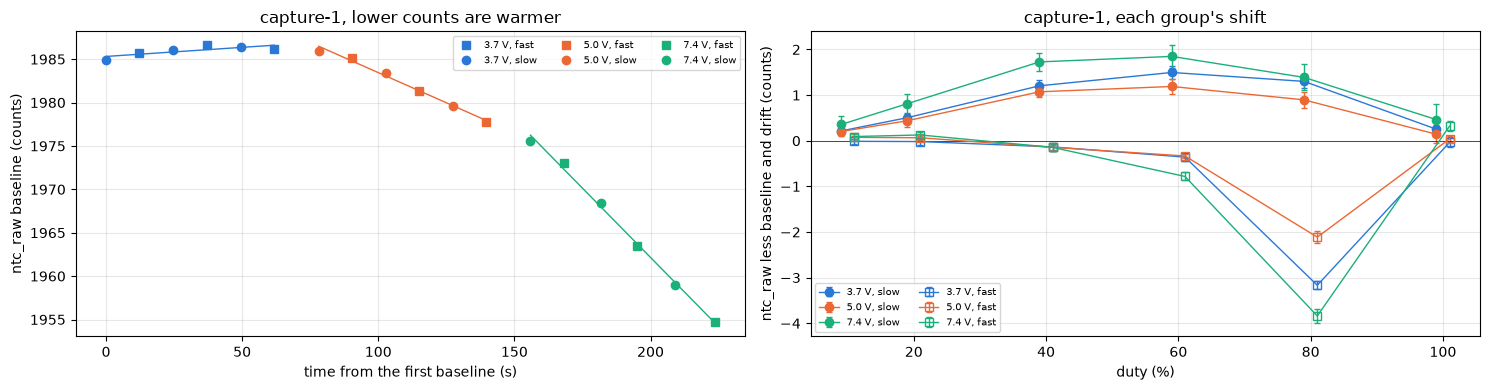

In [42]:
REST1["t"] = REST1["t_base_abs"] - REST1["t_base_abs"].min()
first, last = REST1["ntc_raw_base"].iloc[0], REST1["ntc_raw_base"].iloc[-1]
print(f"baselines {first:.1f} to {last:.1f} counts over "
      f"{REST1['t'].iloc[-1]:.0f} s, {BOARD.ntc_c_beta(first):.2f} to "
      f"{BOARD.ntc_c_beta(last):.2f} C")
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for v, g in REST1.groupby("rail"):
    f = DRIFT[("capture-1", "ntc_raw")][v]
    for decay, gg in g.groupby("decay"):
        ax[0].plot(gg["t"], gg["ntc_raw_base"], DECAY_MARKER[decay],
                   color=RAIL_COLOR[v], label=f"{v} V, {decay}")
    ax[0].plot(g["t"], f["intercept"] + f["slope"] * g["t"],
               color=RAIL_COLOR[v], lw=1)
for decay in ("slow", "fast"):
    for v, g in G1[G1["decay"] == decay].groupby("rail"):
        dx = -1 if decay == "slow" else 1
        ax[1].errorbar(g["duty"] + dx, g["d_ntc"], capsize=2, lw=1,
                       yerr=np.hypot(g["d_ntc_se"], g["d_ntc_err"]),
                       color=RAIL_COLOR[v], marker=DECAY_MARKER[decay],
                       mfc=RAIL_COLOR[v] if decay == "slow" else "none",
                       label=f"{v} V, {decay}")
ax[1].axhline(0, color=INK, lw=0.5)
ax[0].legend(fontsize=7, ncol=3)
ax[1].legend(fontsize=7, ncol=2)
figures.label(ax[0], x="time from the first baseline (s)",
              y="ntc_raw baseline (counts)",
              title="capture-1, lower counts are warmer")
figures.label(ax[1], x="duty (%)", y="ntc_raw less baseline and drift "
              "(counts)", title="capture-1, each group's shift")
figures.finish(fig)

A count in temperature at this board's reading, and whether the fast 80 % dip is a step or a ramp, its last 20 ms against its first.

In [43]:
raw0 = R1["ntc_raw_base"].mean()
MC_PER_COUNT = (BOARD.ntc_c_beta(raw0 - 0.5)
                - BOARD.ntc_c_beta(raw0 + 0.5)) * 1e3
print(f"at {raw0:.0f} counts, {BOARD.ntc_c_beta(raw0):.2f} C: "
      f"{MC_PER_COUNT:.1f} mC per count; rest-noise's floor "
      f"{REST['ntc_noise']['value']:.2f} counts = "
      f"{REST['ntc_noise']['value'] * MC_PER_COUNT:.0f} mC")
hump = {cap: G[(G["decay"] == "slow") & G["duty"].between(40, 60)]["d_ntc"]
        for cap, G in (("capture-1", G1), ("capture-2", G2))}
print("slow-decay NTC hump at 40-60 %: " + ", ".join(
    f"{cap} {h.min():+.2f} to {h.max():+.2f}" for cap, h in hump.items()))
STEP = {}
for v in RAILS:
    dd = []
    for k in R1[(R1["rail"] == v) & (R1["decay"] == "fast")]["k"].unique():
        df, meta, seg = DATA[("capture-1", int(k))]
        for s in (5, 11):             # the fast 80 % rungs
            x = settled(df, s)["ntc_raw"].to_numpy(float)
            dd.append(x[-400:].mean() - x[:400].mean())
    STEP[v] = (np.mean(dd), se(dd))
    print(f"fast 80 % {v} V: last 20 ms - first 20 ms {np.mean(dd):+.2f} "
          f"+/- {se(dd):.2f} counts, n {len(dd)}")

at 1978 counts, 26.55 C: 22.2 mC per count; rest-noise's floor 1.15 counts = 26 mC
slow-decay NTC hump at 40-60 %: capture-1 +1.07 to +1.85, capture-2 +0.97 to +1.93
fast 80 % 3.7 V: last 20 ms - first 20 ms -0.03 +/- 0.02 counts, n 6
fast 80 % 5.0 V: last 20 ms - first 20 ms -0.03 +/- 0.01 counts, n 6
fast 80 % 7.4 V: last 20 ms - first 20 ms -0.08 +/- 0.04 counts, n 6


The NTC's shifts are electrical steps and not heat. Inside the fast 80 % rungs the last 20 ms sit -0.03 to -0.08 counts from the first, and the dip is absent at 100 % where the current is twice as large. The baselines drift with the board's heating, from 1984.9 to 1954.7 counts over 224 s in capture-1, 26.4 to 27.1 C, at +0.021, -0.139 and -0.319 counts/s at the three rails. Beside the dip at fast 80 % of the edge section, the slow-decay rungs carry a hump at 40 to 60 %, +1.07 to +1.85 counts in capture-1 and +0.97 to +1.93 in capture-2. A count is 22 mC at this reading with ntc-curve's beta, and rest-noise puts the floor at 1.15 counts, so all of it is under 0.1 C.

### The rail and the taps

Capture-1's rail tap and terminal taps in slow decay, where the crest sits inside the drive window from 40 % up. The rail's sag, the load's volts from the tap difference, the bridge path as the rail less the load's volts, and the single taps, each also less the bias node's rise under drive from terminal-chain.

In [44]:
T1 = R1.copy()
up = T1["dir"] > 0                      # direction +1 drives A high
T1["tap_hi"] = np.where(up, T1["vmotor_a"], T1["vmotor_b"])
T1["tap_lo"] = np.where(up, T1["vmotor_b"], T1["vmotor_a"])
T1["rest_hi"] = np.where(up, T1["vmotor_a_base"], T1["vmotor_b_base"])
T1["rest_lo"] = np.where(up, T1["vmotor_b_base"], T1["vmotor_a_base"])
T1["rail_v"] = S.rail_v(T1["vbus_raw"])
T1["sag_v"] = S.rail_v(T1["vbus_raw_base"]) - T1["rail_v"]
T1["v_load"] = S.volts(T1["dir"] * (T1["vmotor_a"] - T1["vmotor_b"]),
                       S.terminal_offset_counts)
T1["path_v"] = T1["rail_v"] - T1["v_load"]
T1["v_hi"] = BOARD.term_v(T1["tap_hi"], T1["rest_hi"])
T1["v_lo"] = BOARD.term_v(T1["tap_lo"], T1["rest_lo"])
T1["hs_v"], T1["ls_v"] = T1["rail_v"] - T1["v_hi"], T1["v_lo"]
# terminal-chain: the bias node rises per volt of high leg over it, and the
# single-tap formula then reads each terminal (r - 1) times the rise high
vb_v = TC["bias_rest_meter_v"]["value"]
rise = TC["bias_rise_mv_per_v"]["value"] / 1e3 * (T1["v_hi"] - vb_v)
T1["vb_err_v"] = (BOARD.div_ratio - 1) * rise
T1["hs_v_c"] = T1["hs_v"] + T1["vb_err_v"]
T1["ls_v_c"] = T1["ls_v"] - T1["vb_err_v"]
# the node averaging its legs over the period: the rise scales with duty
T1["vb_err_d_v"] = T1["vb_err_v"] * T1["duty"] / 100
T1["hs_v_d"] = T1["hs_v"] + T1["vb_err_d_v"]
T1["ls_v_d"] = T1["ls_v"] - T1["vb_err_d_v"]
SLOW = T1[T1["decay"] == "slow"]
WIN = SLOW[SLOW["duty"] >= RAIL_FROM_DUTY]
FULL1 = SLOW[SLOW["duty"] == 100]

The lines against the crest current, per rail over 40 to 100 % and across the rails at 100 %.

In [45]:
def line(x, y, name, unit="V"):
    f = results.fit_line(x, y)
    print(f"  {name}: {f['slope']:+.4f} +/- {f['slope_se']:.4f} {unit}/A, "
          f"intercept {f['intercept']:+.4f} +/- {f['intercept_se']:.4f}, "
          f"rms {f['rms']:.4f}, n {f['n']}")
    return f


TAPS = {}
print("rail sag, slow 40-100 %, and the bridge path")
for v, g in WIN.groupby("rail"):
    TAPS[("sag", v)] = line(g["i_crest_a"], g["sag_v"], f"{v} V sag")
    TAPS[("path", v)] = line(g["i_crest_a"], g["path_v"], f"{v} V path")
    for c in ("hs_v_d", "ls_v_d"):
        TAPS[(c, v)] = line(g["i_crest_a"], g[c], f"{v} V {c}")
print("100 % across the rails")
for c in ("sag_v", "path_v", "hs_v_c", "ls_v_c"):
    TAPS[(c, "100")] = line(FULL1["i_crest_a"], FULL1[c], c)
print(f"terminal-chain at the connector: "
      f"{TC['rail_sag_v_per_a']['value']:.4f} +/- "
      f"{TC['rail_sag_v_per_a']['value'] - TC['rail_sag_v_per_a']['lo']:.4f}"
      f" V/A + {TC['rail_sag_offset_v']['value'] * 1e3:.0f} mV; low-side "
      f"return {TC['return_path_ohm']['value']:.3f} ohm, bridge-states' "
      f"loop {BRIDGE['low_side_loop_ohm']['value']:.3f} ohm")
off = SLOW[SLOW["duty"] < RAIL_FROM_DUTY].groupby(["duty", "rail"])
print("10-20 %, the rail slot in the off phase: sag " + ", ".join(
    f"{d} % {v} V {s * 1e3:.1f} mV" for (d, v), s in off["sag_v"].mean()
    .items()))

rail sag, slow 40-100 %, and the bridge path
  3.7 V sag: +0.1811 +/- 0.0037 V/A, intercept +0.0624 +/- 0.0017, rms 0.0024, n 24
  3.7 V path: +0.3222 +/- 0.0085 V/A, intercept +0.0212 +/- 0.0039, rms 0.0056, n 24
  3.7 V hs_v_d: -0.0068 +/- 0.0094 V/A, intercept +0.0619 +/- 0.0043, rms 0.0062, n 24
  3.7 V ls_v_d: +0.3292 +/- 0.0059 V/A, intercept -0.0520 +/- 0.0027, rms 0.0039, n 24
  5.0 V sag: +0.1653 +/- 0.0031 V/A, intercept +0.0740 +/- 0.0020, rms 0.0028, n 24
  5.0 V path: +0.3138 +/- 0.0059 V/A, intercept +0.0305 +/- 0.0037, rms 0.0053, n 24
  5.0 V hs_v_d: -0.0060 +/- 0.0060 V/A, intercept +0.0711 +/- 0.0038, rms 0.0054, n 24
  5.0 V ls_v_d: +0.3201 +/- 0.0051 V/A, intercept -0.0525 +/- 0.0032, rms 0.0045, n 24
  7.4 V sag: +0.1656 +/- 0.0024 V/A, intercept +0.0769 +/- 0.0023, rms 0.0032, n 24
  7.4 V path: +0.3158 +/- 0.0084 V/A, intercept +0.0423 +/- 0.0078, rms 0.0111, n 24
  7.4 V hs_v_d: -0.0081 +/- 0.0067 V/A, intercept +0.0913 +/- 0.0063, rms 0.0090, n 24
  7.4 V ls_v_

The legs against each other, direction +1 less direction -1 per rail, duty and repeat, and fast decay at the crest, which sits in the off phase there.

In [46]:
SYM = {}
for col, scale, unit in (("v_load", 1e3, "mV"), ("hs_v", 1e3, "mV"),
                         ("ls_v", 1e3, "mV"), ("i_crest_a", 1e3, "mA")):
    p = SLOW.pivot_table(index=["rail", "duty", "repeat"], columns="dir",
                         values=col)
    d = (p[1] - p[-1]) * scale
    SYM[col] = d
    rung = d.groupby(level=["rail", "duty"]).mean()   # over the repeats
    print(f"{col}: (+1) - (-1) mean {d.mean():+.2f} {unit}, sd "
          f"{d.std():.2f}, n {len(d)}, per rail and duty "
          f"{rung.min():+.2f} to {rung.max():+.2f}")
F1 = T1[(T1["decay"] == "fast") & (T1["duty"] < 100)].copy()
F1["v_up"] = BOARD.term_v(F1["tap_lo"], F1["rest_lo"])   # pulled over
F1["v_dn"] = BOARD.term_v(F1["tap_hi"], F1["rest_hi"])   # pulled under
F1["up_over_rail"] = F1["v_up"] - F1["rail_v"]
F1["diff_over_rail"] = -F1["v_load"] - F1["rail_v"]
F1["return_a"] = -F1["i_crest_nodrive_a"]
FAST1 = F1.groupby(["rail", "duty"])[["v_up", "v_dn", "up_over_rail",
                                      "diff_over_rail", "return_a"]].mean()
show(FAST1.reset_index(), n=None)

v_load: (+1) - (-1) mean +5.04 mV, sd 4.09, n 54, per rail and duty +0.24 to +14.04
hs_v: (+1) - (-1) mean -7.88 mV, sd 1.96, n 54, per rail and duty -12.48 to -5.28
ls_v: (+1) - (-1) mean -7.88 mV, sd 2.36, n 54, per rail and duty -13.08 to -4.95
i_crest_a: (+1) - (-1) mean +0.66 mA, sd 0.99, n 54, per rail and duty -0.69 to +3.35


,rail,duty,v_up,v_dn,up_over_rail,diff_over_rail,return_a
0,3.700,10,0.641,0.637,-3.045,-3.673,-0.002
1,3.700,20,0.667,0.654,-3.018,-3.663,-0.002
2,3.700,40,1.118,0.399,-2.564,-2.954,-0.002
3,3.700,60,4.563,-0.500,0.874,1.381,0.037
4,3.700,80,4.655,-0.652,0.967,1.626,0.308
5,5.000,10,0.653,0.648,-4.326,-4.965,-0.005
6,5.000,20,0.682,0.682,-4.296,-4.968,-0.006
7,5.000,40,5.478,0.845,0.502,-0.336,-0.005
8,5.000,60,5.944,-0.472,0.949,1.427,0.063
9,5.000,80,6.077,-0.637,1.075,1.719,0.431


Capture-1's slow-decay groups against the crest current, the rail's sag, the bridge path and the single taps, and the bridge path's residuals per rail.

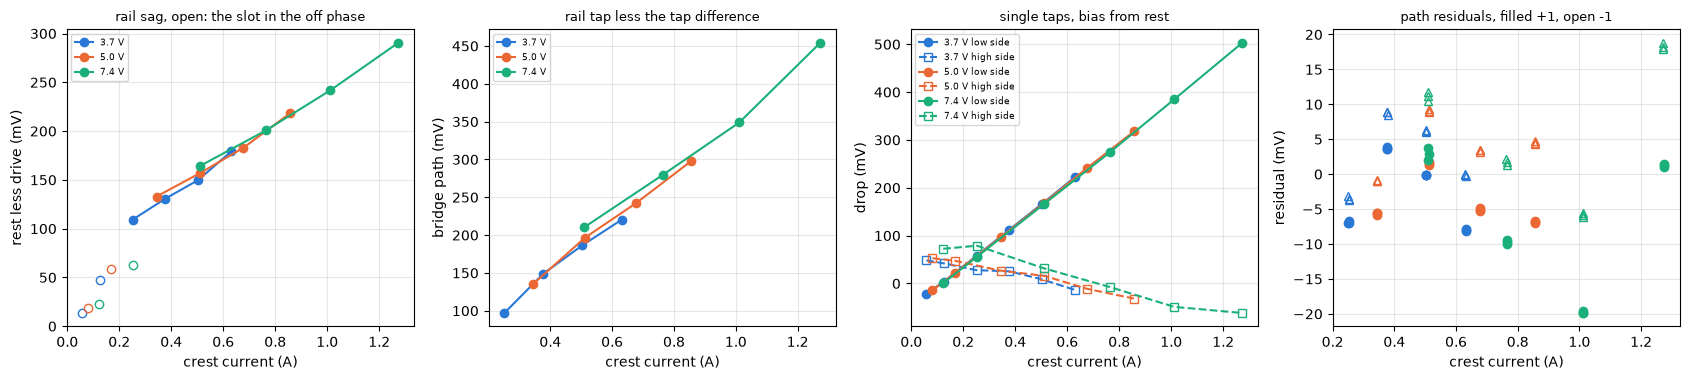

In [47]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.9))
for v, g in SLOW.groupby("rail"):
    c = RAIL_COLOR[v]
    m = g.groupby("duty").mean(numeric_only=True)
    on = m.index >= RAIL_FROM_DUTY
    ax[0].plot(m["i_crest_a"][on], m["sag_v"][on] * 1e3, "o-", color=c,
               label=f"{v} V")
    ax[0].plot(m["i_crest_a"][~on], m["sag_v"][~on] * 1e3, "o", color=c,
               mfc="none")
    ax[1].plot(m["i_crest_a"][on], m["path_v"][on] * 1e3, "o-", color=c,
               label=f"{v} V")
    ax[2].plot(m["i_crest_a"], m["ls_v"] * 1e3, "o-", color=c,
               label=f"{v} V low side")
    ax[2].plot(m["i_crest_a"], m["hs_v"] * 1e3, "s--", color=c, mfc="none",
               label=f"{v} V high side")
    w = g[g["duty"] >= RAIL_FROM_DUTY]
    f = TAPS[("path", v)]
    for d in (1, -1):
        sel = (w["dir"] == d).to_numpy()
        ax[3].plot(w["i_crest_a"][sel], f["resid"][sel] * 1e3,
                   **figures.direction_style(d, c))
titles = ["rail sag, open: the slot in the off phase",
          "rail tap less the tap difference", "single taps, bias from rest",
          "path residuals, filled +1, open -1"]
ylabels = ["rest less drive (mV)", "bridge path (mV)", "drop (mV)",
           "residual (mV)"]
for a, title, y in zip(ax, titles, ylabels):
    figures.label(a, x="crest current (A)", y=y, title=title)
    a.title.set_fontsize(9)
for a in ax[:3]:
    a.legend(fontsize=6.5)
figures.finish(fig)

The rail sags at 100 % by 0.173 +/- 0.001 V/A plus 70 +/- 1 mV across the rails, 42.9 counts per amp with 1.4 mV rms over 18 rungs, and per rail over 40 to 100 % by 0.181, 0.165 and 0.166 V/A. Terminal-chain's meter at the connector read 0.149 +/- 0.002 V/A plus 70 mV, so the rail tap sees 24 +/- 3 mohm more beyond the connector. The fixed 70 mV and the slope steepest at low current fit the feed diode, a candidate. At 10 and 20 % the rail sample falls in the off phase and shows only 13 to 63 mV.

The bridge path, the rail less the tap difference, reads 0.322 +/- 0.009, 0.314 +/- 0.006 and 0.316 +/- 0.008 ohm over 40 to 100 % at each rail, its residuals within about +/-20 mV and split by direction, not by duty. Across the rails at 100 % it reads 0.365 +/- 0.006 ohm, which folds in the two divider chains' ratio mismatch times the rail, a known trap, so the per-rail slopes are the path.

The split between the high and the low side is not resolved, since the bias node rises with the drive. With the rise taken off, the low side reads 0.31 to 0.33 ohm against the meter's 0.305 and bridge-states' 0.301 low-side loop, so the tap's ground and the ADC's ground agree to about 0.03 ohm if the bias-rise model holds, with low-medium confidence. The high side reads 0 to 0.06 ohm against the datasheet's 0.14 typical.

The legs are symmetric. Direction +1 less direction -1 reads +5.0 mV on the load's volts, sd 4.1 and at most +14 mV, under 0.2 %, -7.9 mV on each single tap's drop and +0.7 mA on the current.

In fast decay the crest sits in the off phase. At 60 and 80 % the return flows the whole period, the driven-low leg sits 0.87 to 1.31 V over the rail tap and the driven-high leg 0.43 to 0.65 V under ground, and the tap difference sits 1.38 to 1.91 V over the rail, two body diodes at 0.7 to 0.95 V each, rising with the 0.04 to 0.66 A of return. At 10 and 20 % both terminals float together at +0.64 to +0.72 V.

### The dummy

Which RL dummy was on the terminals. The 100 % rungs' V/I against bridge-states' four wirings, and the time constant of the current's rise at the 100 % onsets, each period's crest closing on the settled current by a fixed ratio per 50 us period.

In [48]:
VI = S.volts(H1["dir"] * (H1["vmotor_a"] - H1["vmotor_b"]),
             S.terminal_offset_counts) / H1["i_crest_a"]
print(f"100 % V/I: {VI.mean():.4f} +/- {se(VI):.4f} ohm (sd {VI.std():.4f},"
      f" n {len(VI)})")
for w, q in BRIDGE["dc_r_ohm"].items():
    print(f"  bridge-states {w}: {q['value']:.4f} ohm")
taus = []
for k, sw in SWEEPS["capture-1"].set_index("k").iterrows():
    df, meta, seg = DATA[("capture-1", int(k))]
    zero = tel.baseline(df)["current_raw"].median()
    for s in FULL:
        g = df[df["seg"] == s].reset_index(drop=True)
        apart = (g["vmotor_a"] - g["vmotor_b"]).abs().to_numpy()
        i0 = int(np.flatnonzero(apart > EDGE_COUNTS)[0])
        if i0 < 1:
            continue
        x = g["current_raw"].to_numpy(float) - zero
        level = x[SKIP:].mean()
        # rows i0 + 1 to i0 + 6: the share still to come, period by period
        left = (level - x[i0 + 1:i0 + 7]) / level
        ok = left > 0.03
        slope = np.polyfit(np.arange(len(left))[ok], np.log(left[ok]), 1)[0]
        taus.append({"rail": sw["volts_set"], "tau_us": -50 / slope})
TAU = pd.DataFrame(taus)
L_MH = TAU["tau_us"].mean() * VI.mean() / 1000
print(f"rise time constant {TAU['tau_us'].mean():.0f} +/- "
      f"{se(TAU['tau_us']):.0f} us, n {len(TAU)}; L {L_MH:.2f} mH; "
      f"bridge-states one inductor {BRIDGE['tau_us']['ra_25']['value']:.0f}"
      f" us, both {BRIDGE['tau_us']['rab_25']['value']:.0f} us")

100 % V/I: 5.2177 +/- 0.0005 ohm (sd 0.0027, n 36)
  bridge-states r: 5.0847 ohm
  bridge-states ra: 5.2237 ohm
  bridge-states rab: 5.3431 ohm
  bridge-states rb: 5.2281 ohm
rise time constant 168 +/- 1 us, n 30; L 0.88 mH; bridge-states one inductor 200 us, both 392 us


The dummy was the resistor plus one inductor. Its V/I at 100 % reads 5.218 +/- 0.001 ohm over 36 rungs, against bridge-states' 5.224 and 5.228 ohm with one inductor and 5.343 with both, and its rise time constant reads 168 +/- 1 us over 30 onsets, L 0.88 mH, against bridge-states' 200 us on one inductor and 392 on both. That is high confidence. No conclusion here depends on L.

### The results file

The DC coupling and what it gives at the locked laps' current, the partial-duty bound and its repeat, the onset's VDD dip, the frame ripple and the pot's floor, the noise under drive, the edge disturbances, the NTC, the rail and the taps, and the dummy. Rails are keyed as 3v7, 5v0 and 7v4.

In [49]:
q, pm = results.q, results.pm


def per_rail(values, unit, err=None):
    # {3v7: q, ...} from {rail: value} and optional {rail: error}
    return {rail_key(v): q(x, unit=unit) if err is None
            else pm(x, err[v], unit) for v, x in values.items()}


pooled, c2dir = DC["pooled"], DIR_GAP["capture-2"]
quantities = {
    "pos_dc_coupling_counts_per_a": results.line_q(pooled, "slope",
                                                   "counts/A"),
    "pos_dc_coupling_through_zero_counts_per_a": pm(
        pooled["b0"], pooled["b0_se"], "counts/A"),
    "pos_dc_intercept_counts": results.line_q(pooled, "intercept",
                                              "counts"),
    "pos_dc_coupling_by_capture_counts_per_a": {
        cap.replace("-", "_"): results.line_q(DC[cap], "slope", "counts/A")
        for cap in CAPTURES},
    "pos_dc_coupling_by_direction_counts_per_a": {
        f"dir_{'p' if d > 0 else 'm'}1": results.line_q(
            DIR_SLOPE[("capture-2", d)], "slope", "counts/A")
        for d in (1, -1)},
    "pos_dc_residual_rms_counts": q(pooled["rms"], unit="counts"),
    "pos_rest_rail_slope_counts_per_v": results.line_q(
        REST_RAIL, "slope", "counts/V"),
    "pos_at_0p77a_counts": pm(pooled["at_locked"],
                              pooled["at_locked_se"], "counts"),
    "pos_direction_asymmetry_counts": results.mean_sd(c2dir, "counts"),
    "pos_capture_repeat_slope": results.line_q(REPEAT, "slope", "ratio"),
    "pos_capture_repeat_rms": q(REPEAT["rms_diff"], unit="counts"),
    "pos_capture_repeat_corr": q(REPEAT["corr"], unit="ratio"),
}

The partial-duty bound.

In [50]:
quantities.update({
    "ntc_capture_repeat_slope": results.line_q(NTC_REPEAT, "slope",
                                               "ratio"),
    "pos_partial_duty_max_counts": pm(top["d_pos"], top["d_pos_se"],
                                      "counts"),
    "pos_partial_duty_max_at": {"decay": top["decay"],
                                "duty": q(top["duty"], unit="%"),
                                "rail": q(top["rail"], unit="V")},
    "pos_partial_duty_group_range_counts": q(
        BY_DIR1.max(), BY_DIR1.min(), BY_DIR1.max(), "counts"),
    "pos_fast_bump_rail_slope_counts_per_v": {
        f"{d}pct": results.line_q(EXCESS[("fast", d)], "slope", "counts/V")
        for d in (10, 60)},
    "pos_rung_half_diff_sd_counts": q(P1["half_diff"].std(), unit="counts"),
})

The onset, the frame pattern and the noise under drive.

In [51]:
on = ONSET.set_index("rail")
quantities.update({
    "vdd_onset_dip_mv": per_rail(on["dip_mv"], "mV", on["dip_se"]),
    "vdd_onset_half_width_us": per_rail(on["half_us"], "us"),
    "vdd_onset_settle_us": per_rail(on["settle_us"], "us"),
    "vref_onset_peak_pct": per_rail(on["vref_raw_pct"], "%",
                                    on["vref_raw_se"]),
    "pos_onset_peak_pct": per_rail(on["pos_pct"], "%", on["pos_se"]),
    "ntc_onset_peak_pct": per_rail(on["ntc_raw_pct"], "%",
                                   on["ntc_raw_se"]),
    "pos_onset_share_of_vref": per_rail(on["pos_of_vref"], "ratio"),
    "pos_onset_peak_counts": per_rail(
        {v: p[0] for v, p in POS_PEAK.items()}, "counts",
        {v: p[1] for v, p in POS_PEAK.items()}),
    "vdd_dc_drop_100pct_mv": per_rail(VDD_DC, "mV"),
    "vdd_frame_ripple_mv_pp": pm(RIPPLE["pp"], RIPPLE["pp_se"], "mV"),
    "vdd_frame_ripple_mv_rms": q(RIPPLE["rms"], unit="mV"),
    "pos_rest_sd_counts": {cap.replace("-", "_"): results.mean_se(
        FLOOR[cap]["sd"], "counts") for cap in CAPTURES},
    "pos_rest_sd_pattern_removed_counts": {
        cap.replace("-", "_"): results.mean_se(FLOOR[cap]["resid_sd"],
                                               "counts")
        for cap in CAPTURES},
    "pos_frame_share_over_vref": results.mean_se(OVER_VREF["pos"], "ratio"),
    "ntc_frame_share_over_vref": results.mean_se(OVER_VREF["ntc_raw"],
                                                 "ratio"),
    "rail_frame_share_over_vref": results.mean_se(OVER_VREF["vbus_raw"],
                                                  "ratio"),
    "pos_frame_corr_with_vref": q(CORR["pos"].mean(), CORR["pos"].min(),
                                  CORR["pos"].max(), "ratio"),
    "pos_frame_pp_rest_counts": q(DRIVE_PP["pos"][2], unit="counts"),
    "pos_frame_pp_drive_counts": q(DRIVE_PP["pos"][3], DRIVE_PP["pos"][0],
                                   DRIVE_PP["pos"][1], "counts"),
    "vref_frame_pp_rest_counts": q(DRIVE_PP["vref_raw"][2], unit="counts"),
    "vref_frame_pp_drive_counts": q(DRIVE_PP["vref_raw"][3],
                                    DRIVE_PP["vref_raw"][0],
                                    DRIVE_PP["vref_raw"][1], "counts"),
})

The rest of the noise and the edges.

In [52]:
for name in ("pos", "ntc", "vref", "rail", "shunt"):
    r = NOISE.loc[name]
    quantities[f"{name}_sd_rest_counts"] = pm(r["rest"], r["rest_se"],
                                             "counts")
    quantities[f"{name}_sd_drive_counts"] = pm(r["drive"], r["drive_se"],
                                              "counts")
pos_n, taps_n = NOISE.loc["pos"], NOISE.loc["taps"]
fast40 = DRIVE_N[(DRIVE_N["decay"] == "fast") & (DRIVE_N["duty"] == 40)]
quantities.update({
    "pos_sd_drive_range_counts": q(pos_n["drive"], pos_n["lo"],
                                   pos_n["hi"], "counts"),
    "pos_sd_rest_raw_counts": q(pos_n["rest_raw"], unit="counts"),
    "pos_sd_drive_raw_counts": q(pos_n["drive_raw"], unit="counts"),
    "tap_sd_rest_counts": pm(taps_n["rest"], taps_n["rest_se"], "counts"),
    "tap_sd_drive_slow_counts": q(taps_n["slow"], unit="counts"),
    "tap_sd_fast40_counts": {c: q(fast40[fast40["ch"] == c]["resid_sd"]
                                  .mean(), unit="counts")
                             for c in ("vmotor_a", "vmotor_b")},
    "pos_vref_prediction_slope": results.line_q(VREF_PRED, "slope",
                                                "ratio"),
    "pos_rung_shift_rms_counts": {k: q(v, unit="counts")
                                  for k, v in SCALED_RMS.items()},
    "slot_aperture_ticks": {ch: q(c, o, c, "ticks after the crest")
                            for ch, (o, c) in SLOTS.items()},
})
names = {"vref slow 10 % dir -1": ("vref_slow10_dir_m1_counts", "d_vref"),
         "vref fast 40 % dir +1": ("vref_fast40_dir_p1_counts", "d_vref"),
         "vref fast 80 % dir -1": ("vref_fast80_dir_m1_counts", "d_vref"),
         "ntc fast 80 % both dirs": ("ntc_fast80_dip_counts", "d_ntc")}
for name, (key, col) in names.items():
    g = DISTURB[name]
    quantities[key] = per_rail(g[col], "counts", g[col + "_se"])
dip = DISTURB["ntc fast 80 % both dirs"]
quantities["ntc_fast80_dip_mc"] = per_rail(
    -dip["d_ntc"] * MC_PER_COUNT, "mC, the apparent warming",
    dip["d_ntc_se"] * MC_PER_COUNT)

The NTC.

In [53]:
quantities["ntc_mc_per_count"] = q(MC_PER_COUNT, unit="mC/count")
quantities["ntc_drift_counts_per_s"] = {
    rail_key(v): results.line_q(f, "slope", "counts/s")
    for v, f in DRIFT[("capture-1", "ntc_raw")].items()}
quantities["ntc_fast80_step_counts"] = per_rail(
    {v: s[0] for v, s in STEP.items()}, "counts",
    {v: s[1] for v, s in STEP.items()})

The rail, the taps and the dummy.

In [54]:
sag = TAPS[("sag_v", "100")]
meter = TC["rail_sag_v_per_a"]
beyond = sag["slope"] - meter["value"]
beyond_se = np.hypot(sag["slope_se"], meter["value"] - meter["lo"])
over = FAST1.loc[FAST1.index.get_level_values("duty") >= 60]
quantities.update({
    "rail_sag_v_per_a": results.line_q(sag, "slope", "V/A"),
    "rail_sag_offset_mv": results.line_q(sag, "intercept", "mV", 1e3),
    "rail_sag_counts_per_a": q(sag["slope"] * S.rail_counts_per_v,
                               unit="counts/A"),
    "rail_sag_by_rail_v_per_a": {rail_key(v): results.line_q(
        TAPS[("sag", v)], "slope", "V/A") for v in RAILS},
    "rail_sag_beyond_connector_ohm": pm(beyond, beyond_se, "ohm"),
    "bridge_path_ohm": {rail_key(v): results.line_q(
        TAPS[("path", v)], "slope", "ohm") for v in RAILS},
    "bridge_path_across_rails_ohm": results.line_q(
        TAPS[("path_v", "100")], "slope", "ohm"),
    "low_side_ohm": {rail_key(v): results.line_q(
        TAPS[("ls_v_d", v)], "slope", "ohm") for v in RAILS},
    "high_side_ohm": {rail_key(v): results.line_q(
        TAPS[("hs_v_d", v)], "slope", "ohm") for v in RAILS},
    "leg_asymmetry_mv": results.mean_sd(SYM["v_load"], "mV"),
    "fast_tap_difference_over_rail_v": results.median_range(
        over["diff_over_rail"], "V", value=over["diff_over_rail"].mean()),
    "dummy_r_ohm": pm(VI.mean(), se(VI), "ohm"),
    "dummy_tau_us": pm(TAU["tau_us"].mean(), se(TAU["tau_us"]), "us"),
    "dummy_l_mh": q(L_MH, unit="mH"),
})

The notes the results file carries, and the write.

In [55]:
NOTES = (
    "board D with a 3.3 k / 2.2 k divider on the POS connector in the pot's "
    "place and the RL dummy, the resistor plus one inductor, on the motor "
    "terminals; capture-1 rows pos, rail, NTC, shunt and both taps, "
    "capture-2 trades tap B for vref_raw; 18 sweeps each, 3.7, 5.0 and "
    "7.4 V, slow and fast decay, 3 repeats, 10 to 100 % both directions; a "
    "rung is its rows 200 to 6000 less its sweep's torque-off baseline, the "
    "second half; NTC and vref drift out by one line per rail through the "
    "baselines; bounds are one standard error unless a key says range or "
    "sd: *_range_*, *_corr_*, slot_aperture_ticks and "
    "fast_tap_difference_over_rail_v are the lowest to highest, "
    "pos_direction_asymmetry_counts and leg_asymmetry_mv one sd either "
    "side, *_frame_pp_drive_counts the mean and range of the decay and "
    "duty groups under drive; onsets "
    "are the 100 % rungs aligned on the drive's first row with the frame "
    "pattern out, VDD dip = VDD s / (1 + s) from vref_raw's share s with "
    "terminal-chain's VDD; noise sd is per window with its own tick % 16 "
    "pattern out, both captures pooled; per-group standard errors "
    "understate the 0.1 count run-to-run floor")
path = results.write("1-board", "pos-coupling", DATASET, pair=BOARD.key,
                     notes=NOTES, **quantities)
print("wrote", path)

wrote stages/1-board/pos-coupling/results/dev-v006-2A-D.json


## Verdicts and fixes

- The DC `pos` coupling, +0.5 counts per amp. No fix. The board is cleared for the locked-horn shift, which was the lock's own play. The rig's lock needs a fitting hole and a seated nut before any capture that reads the pot under a locked horn. No firmware number is touched.
- (a) The VDD onset dip. It puts +20 counts on `pos` for about 0.5 ms at 3.7 V and +7 for 0.15 to 0.2 ms at 5 and 7.4 V, about 3 samples of a step, which a 20 kHz position loop sees. The first step is a measurement, the swap board at 3.7 V before any change. With no feed diode it gains the 70 mV step plus 0.17 V/A of headroom, so it should land between board D's 3.7 V and 5 V cases, a candidate. If the dip persists, output capacitance on the 3V3 regulator and a check of its dropout at the lowest rail. In firmware, `pos` times $n_\mathrm{ref,0} / n_\mathrm{ref}$ would remove 80 to 94 % of the onset, but it needs a `vref_raw` sample free of (c) first, from the trough scan or away from the bad duties. It touches the position estimator's input during current steps. No fix is warranted until the swap board is measured.
- (b) The frame-rate VDD ripple, 5.0 mV peak to peak. It raises the pot's floor from 0.66 to about 1.1 counts rms, so stage 3's 1-count floor is partly this artifact. The first step is a measurement, `pos` at rest with the TEL stream quiet, a DMA record, which needs a row change since today's bursts carry no `pos`. If the floor falls to 0.66 the ripple is the stream's own load on 3V3 and exists only while streaming. If it is not the stream's, decoupling at the transceiver and at the MCU's 3V3 is the hardware fix. For analysis now, the tick % 16 pattern comes out offline. It touches the `pos` variance in stage 3's filter and observer weights, 0.66 counts once confirmed.
- (c) The edge-proximity disturbances. The NTC's dip of up to -3.8 counts, about 85 mC, at fast 80 % needs no fix. `vref_raw`'s up to +17.8 counts, 1.2 %, at slow 10 % in direction -1 matters only if firmware uses a crest-scan `vref_raw`. The firmware fix is to read it from the trough scan or at rest, or to skip it where an edge lands within about 40 to 420 ticks of its aperture, and no hardware fix is warranted. The 1 to 1.7 counts steady on `pos` at partial duty are not locked to an edge and not VDD at the reference's instant, the mechanism is open and the size is at the 1-count floor, so there is no fix and no further test, and it is carried as a bound. Stage 3's pot-table comparisons under drive carry it as up to +1.7 counts, the same in both directions, by duty and decay.
- The noise under drive. The bridge adds nothing to the noise of `pos`, the NTC and `vref_raw`, so the `pos` sample variance under drive is the rest value.

## Open questions

- Whether the onset dip follows the regulator's headroom ((a)). The feed diode and the regulator's dropout on the low rail are the candidates, and output capacitance on the 3V3 regulator the other. The same sweeps on the swap board at 3.7 V, with `vref_raw` in the row, put the dip between board D's 3.7 V and 5 V cases if the headroom owns it.
- Whether the frame ripple is the stream's own load on 3V3 ((b)). A DMA record of `pos` at rest with the TEL stream quiet reads 0.66 counts if it is, and about 1.1 if it is not. `pos`'s 24 % of pattern beyond VDD's share is not explained by this data.
- What owns the rail tap's 24 mohm and 70 mV beyond the connector. The feed diode is the candidate, and the swap board, with no diode, reads the sag without it.
- The split of the bridge path between the high and the low side. The bias node rises with the drive, and the low side's 0.31 to 0.33 ohm agrees with the meter only if the bias-rise model holds. Terminal-chain's open question, a meter on the bias node during a lap, reads the rise directly.
- The partial-duty shift on `pos`, up to +1.7 counts. Its mechanism stays open and it is carried as a bound.

## Conclusion

With a fixed divider in the pot's place and nothing able to move, board D couples +0.5 +/- 0.1 counts per amp into `pos` at DC, the same sign in both directions, 0.563 +/- 0.033 counts/A over both captures. At the locked laps' 0.77 A that is +0.32 +/- 0.04 counts, so the -7.4 counts of the locked horn are not the board, and the bench traced them to the lock's play, mechanical with high confidence. The steps notebook's -1 leg offset is not the board either, since `pos` reads the same in both directions here to 0.07 counts.

Under switching `pos` carries steady shifts of up to +1.7 counts by duty and decay, repeated across two captures to 0.03 counts, not locked to any edge and not a VDD move common to the period, carried as a bound. Three effects come from VDD and the bridge's edges. Each rung's onset dips VDD by 49 mV at 3.7 V and 14 to 19 mV at 5 and 7.4 V, which puts +20 and +7 counts on `pos` for a fraction of a millisecond. A 5.0 mV ripple on VDD at the TEL frame raises the pot's floor from 0.66 to 1.1 counts rms. Edges near a slot's aperture move the NTC by up to -3.8 counts and a crest-scan `vref_raw` by up to +17.8 counts in one direction. The switching adds nothing to the noise of `pos`, the NTC or `vref_raw`, 0.63 counts rms on `pos` under drive with the pattern out against 0.66 at rest. The NTC's shifts are all under 0.1 C, the rail sags by 0.173 V/A plus 70 mV at its tap, the legs match to 5 mV, and the dummy was the resistor and one inductor, 5.218 ohm and 168 us. The next steps are measurements, the swap board at 3.7 V for the onset and a TEL-quiet record for the frame ripple.